# Formula 1 Podium Prediction — Milestone 1

**Team 95**

| Name | ID |
|---|---|
| Youssef Mohamed Mahmoud Eid | 52-2413 |
| Omar Khaled Mohamed Mohamed Ghonima | 58-1891 |
| Mohamed Ayman Mohamed Abdelrahman Elsayed | 58-22010 |
| Omar Ahmed Mohamed Mohamed Mohamed Elbehery | 58-16880 |

**Goal:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information that is known **after qualifying and before the race starts**.

**Unit of analysis:** one driver in one race → one row per `(raceId, driverId)`.

Notebook map:
1. Setup & data loading
2. EDA **before** cleaning
3. Data cleaning & auditing (sentinels, semantic typing, primary/foreign keys, duplicate drivers)
4. EDA **after** cleaning (impact of the cleaning)
5. Data-engineering questions (Q1–Q3)
6. Feature engineering & feature selection (leakage-safe)
7. Dataset split (train / validation / test)
8. Pre-processing (+ effect on the data) and pre-processing-order experiments
9. Modeling: baseline + statistical models + shallow neural network
10. Final model comparison (validation and unseen test)
11. Feature-group ablation
12. Explainability (permutation importance, SHAP, LIME)
13. Inference function
14. Conclusions & limitations

In [1]:
!pip install -q shap lime


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.inspection import permutation_importance

import keras
from keras import layers
from keras.callbacks import EarlyStopping

import shap
import lime, lime.lime_tabular

warnings.filterwarnings('ignore')
np.random.seed(42)
keras.utils.set_random_seed(42)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

os.makedirs('figures', exist_ok=True)
def save(name):
    """Save the current figure so it can be reused in the report."""
    plt.savefig(f'figures/{name}.png', dpi=110, bbox_inches='tight')

## 1. Data loading

The dataset is the Kaggle *Formula 1 World Championship (1950–2024)* dataset (14 relational CSV tables).
On Kaggle the files are under `/kaggle/input/...`; outside Kaggle the cell downloads the same dataset with `kagglehub`.

The raw tables are loaded into the dictionary `raw` and **never modified** — all cleaning happens on copies (`clean`).
We load them with `keep_default_na=False` so that we see the data exactly as it is stored (including the `\N` placeholders).

In [3]:
hits = glob.glob('/kaggle/input/**/races.csv', recursive=True)
if hits:
    DATA_DIR = os.path.dirname(hits[0])
elif os.environ.get('F1_DATA_DIR'):  # local copy of the same Kaggle dataset
    DATA_DIR = os.environ['F1_DATA_DIR']
else:  # running outside Kaggle
    import kagglehub
    DATA_DIR = kagglehub.dataset_download('rohanrao/formula-1-world-championship-1950-2020')
print('Data folder:', DATA_DIR)

TABLES = ['circuits', 'constructor_results', 'constructor_standings', 'constructors', 'driver_standings',
          'drivers', 'lap_times', 'pit_stops', 'qualifying', 'races', 'results', 'seasons',
          'sprint_results', 'status']
raw = {t: pd.read_csv(f'{DATA_DIR}/{t}.csv', keep_default_na=False) for t in TABLES}
for t, df in raw.items():
    print(f'{t:22s} {df.shape}')

Data folder: C:\Users\yeid\.cache\kagglehub\datasets\rohanrao\formula-1-world-championship-1950-2020\versions\24


circuits               (77, 9)
constructor_results    (12625, 5)
constructor_standings  (13391, 7)
constructors           (212, 5)
driver_standings       (34863, 7)
drivers                (861, 9)
lap_times              (589081, 6)
pit_stops              (11371, 7)
qualifying             (10494, 9)
races                  (1125, 18)
results                (26759, 18)
seasons                (75, 2)
sprint_results         (360, 16)
status                 (139, 2)


In [4]:
raw['results'].head()

,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId
0,1,18,1,1,22,1,1,1,1,10.0,58,1:34:50.616,5690616,39,2,1:27.452,218.300,1
1,2,18,2,2,3,5,2,2,2,8.0,58,+5.478,5696094,41,3,1:27.739,217.586,1
2,3,18,3,3,7,7,3,3,3,6.0,58,+8.163,5698779,41,5,1:28.090,216.719,1
3,4,18,4,4,5,11,4,4,4,5.0,58,+17.181,5707797,58,7,1:28.603,215.464,1
4,5,18,5,1,23,3,5,5,5,4.0,58,+18.014,5708630,43,1,1:27.418,218.385,1


## 2. EDA before cleaning

First we look at the raw data: size of each table, how many `\N` placeholders (sentinels) it has, and which columns pandas could not read as numbers because of them.

In [5]:
SENTINEL = '\\N'
overview = pd.DataFrame({
    t: {'rows': len(df), 'columns': df.shape[1],
        'sentinel cells (\\N)': int((df == SENTINEL).sum().sum()),
        'text (object) columns': int((df.dtypes == object).sum())}
    for t, df in raw.items()}).T
overview

,rows,columns,sentinel cells (\N),text (object) columns
circuits,77,9,0,5
constructor_results,12625,5,12608,1
constructor_standings,13391,7,0,1
constructors,212,5,0,4
driver_standings,34863,7,0,1
drivers,861,9,1559,8
lap_times,589081,6,0,1
pit_stops,11371,7,0,2
qualifying,10494,9,11600,3
races,1125,18,11349,14


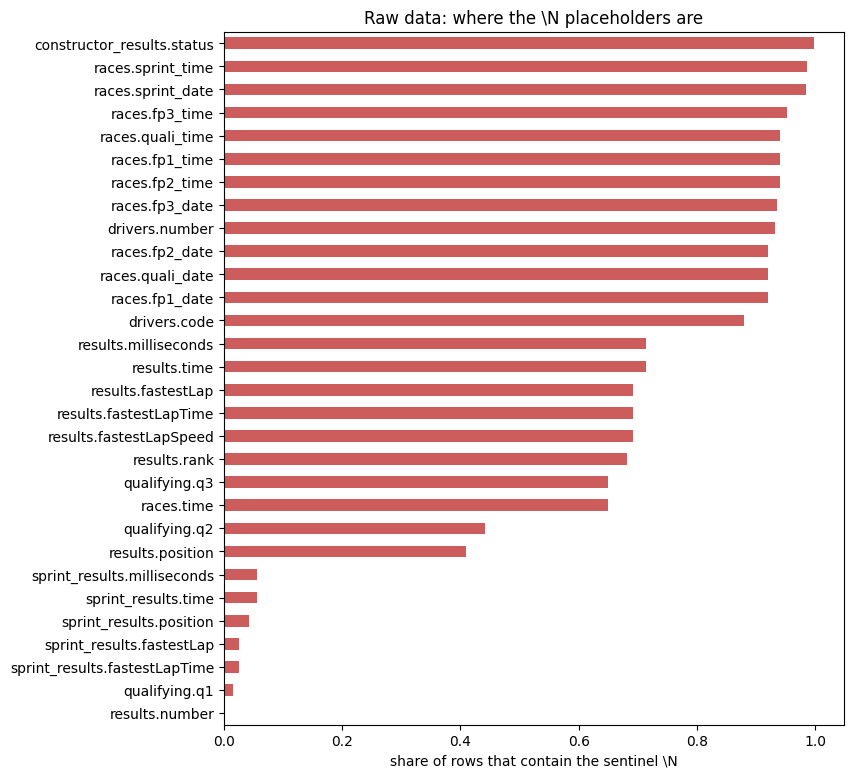

In [6]:
sent = pd.concat({t: (df == SENTINEL).mean() for t, df in raw.items()})
sent = sent[sent > 0].sort_values()
sent.index = [f'{t}.{c}' for t, c in sent.index]

plt.figure(figsize=(8, 9))
sent.plot.barh(color='indianred')
plt.xlabel('share of rows that contain the sentinel \\N')
plt.title('Raw data: where the \\N placeholders are')
save('eda_raw_sentinels')
plt.show()

In [7]:
print('Raw dtypes of results.csv (numbers stored as text because of \\N):')
print(raw['results'].dtypes.to_string())

Raw dtypes of results.csv (numbers stored as text because of \N):
resultId             int64
raceId               int64
driverId             int64
constructorId        int64
number              object
grid                 int64
position            object
positionText        object
positionOrder        int64
points             float64
laps                 int64
time                object
milliseconds        object
fastestLap          object
rank                object
fastestLapTime      object
fastestLapSpeed     object
statusId             int64


Extra rows for the same (raceId, driverId): 91


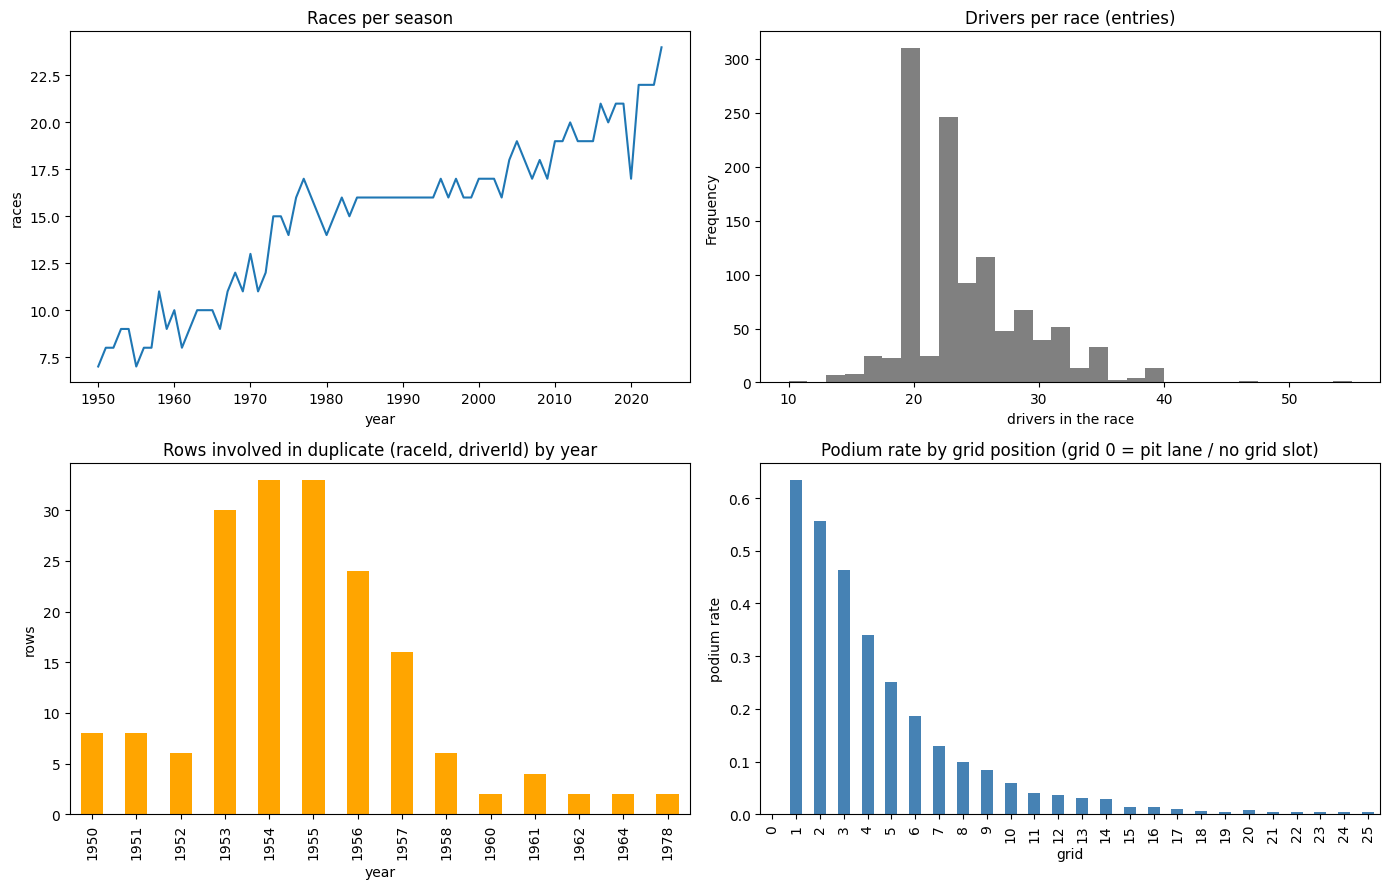

Overall podium rate (all years): 0.127


In [8]:
res_raw = raw['results'].merge(raw['races'][['raceId', 'year']], on='raceId')
dup_rows = res_raw[res_raw.duplicated(['raceId', 'driverId'], keep=False)]
print('Extra rows for the same (raceId, driverId):', res_raw.duplicated(['raceId', 'driverId']).sum())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
raw['races'].groupby('year').size().plot(ax=axes[0, 0])
axes[0, 0].set_title('Races per season'); axes[0, 0].set_ylabel('races')

res_raw.groupby('raceId').size().plot.hist(bins=30, ax=axes[0, 1], color='gray')
axes[0, 1].set_title('Drivers per race (entries)'); axes[0, 1].set_xlabel('drivers in the race')

dup_rows.groupby('year').size().plot.bar(ax=axes[1, 0], color='orange')
axes[1, 0].set_title('Rows involved in duplicate (raceId, driverId) by year'); axes[1, 0].set_ylabel('rows')

pod_by_grid = res_raw.assign(podium=res_raw.positionOrder <= 3).query('grid <= 25').groupby('grid').podium.mean()
pod_by_grid.plot.bar(ax=axes[1, 1], color='steelblue')
axes[1, 1].set_title('Podium rate by grid position (grid 0 = pit lane / no grid slot)')
axes[1, 1].set_ylabel('podium rate')
plt.tight_layout()
save('eda_raw_overview')
plt.show()

print(f"Overall podium rate (all years): {(res_raw.positionOrder <= 3).mean():.3f}")

**What the raw EDA shows**
- `\N` is used as a "missing" placeholder in 6 tables. Because of it, numeric columns such as `results.position`, `results.milliseconds` or `qualifying.q1` were read as **text**, so they cannot be used numerically until cleaned.
- Some sentinels are *real* missing values (e.g. `results.position` is `\N` when the driver did not finish), others mean "did not happen" (e.g. `q3` is empty for drivers knocked out in Q1/Q2).
- Durations are stored as strings like `1:27.452` and dates as strings — they need semantic typing.
- 91 extra rows share the same `(raceId, driverId)` — almost all in the 1950s (shared drives).
- The target is **imbalanced**: only ~13% of entries are podiums, and the podium rate drops very quickly with grid position, so grid/qualifying should be strong predictors.

## 3. Data cleaning & auditing

### 3.1 Sentinel handling and semantic typing
Rules (applied automatically to every table, not by hand):
1. Replace `\N` (and empty strings) with a real missing value `NaN`.
2. Strip extra spaces from text values.
3. If **every** non-missing value of a text column is a number → convert the column to numeric.
4. Date columns (`date`, `*_date`, `dob`) → `datetime`.
5. Duration strings (`m:ss.sss`, `h:mm:ss.sss` or `ss.sss`) → numeric **seconds** (new `*_s` columns).
6. Fix label inconsistencies found in the data: circuit country `United States` vs `USA`, and driver nationality `Argentinian` vs `Argentine`.

In [9]:
def to_seconds(value):
    """'1:27.452' -> 87.452 , '16:44.718' -> 1004.718 , '22.5' -> 22.5 , invalid -> NaN"""
    if pd.isna(value):
        return np.nan
    parts = str(value).split(':')
    try:
        return sum(float(p) * 60 ** i for i, p in enumerate(reversed(parts)))
    except ValueError:
        return np.nan

clean = {}
for t, df in raw.items():
    df = df.copy()
    df = df.replace({SENTINEL: np.nan, '': np.nan})
    for col in df.columns:
        if df[col].dtype == object:
            df[col] = df[col].str.strip()
            as_num = pd.to_numeric(df[col], errors='coerce')
            if as_num.notna().sum() == df[col].notna().sum():   # every value is numeric
                df[col] = as_num
        if col == 'date' or col.endswith('_date') or col == 'dob':
            df[col] = pd.to_datetime(df[col], errors='coerce')
    clean[t] = df

# durations -> seconds
for c in ['q1', 'q2', 'q3']:
    clean['qualifying'][c + '_s'] = clean['qualifying'][c].apply(to_seconds)
clean['results']['fastestLapTime_s'] = clean['results']['fastestLapTime'].apply(to_seconds)
clean['sprint_results']['fastestLapTime_s'] = clean['sprint_results']['fastestLapTime'].apply(to_seconds)
clean['pit_stops']['duration_s'] = clean['pit_stops']['duration'].apply(to_seconds)
clean['lap_times']['time_s'] = clean['lap_times']['milliseconds'] / 1000

# label fixes
clean['circuits']['country'] = clean['circuits']['country'].replace({'United States': 'USA'})
clean['drivers']['nationality'] = clean['drivers']['nationality'].replace({'Argentinian': 'Argentine'})

print('Remaining \\N cells:', sum(int((df == SENTINEL).sum().sum()) for df in clean.values()))
print('\nresults dtypes after cleaning:')
print(clean['results'].dtypes.to_string())

Remaining \N cells: 0

results dtypes after cleaning:
resultId              int64
raceId                int64
driverId              int64
constructorId         int64
number              float64
grid                  int64
position            float64
positionText         object
positionOrder         int64
points              float64
laps                  int64
time                 object
milliseconds        float64
fastestLap          float64
rank                float64
fastestLapTime       object
fastestLapSpeed     float64
statusId              int64
fastestLapTime_s    float64


In [10]:
check = clean['qualifying'][['q1', 'q1_s', 'q3', 'q3_s']].dropna().head(3)
print('Duration conversion check:\n', check, '\n')
print('Date typing check:', clean['races']['date'].dtype, clean['drivers']['dob'].dtype)
print('Pit-stop durations > 60 s (red-flag stops, kept but noted):', (clean['pit_stops'].duration_s > 60).sum())

Duration conversion check:
          q1    q1_s        q3    q3_s
0  1:26.572  86.572  1:26.714  86.714
1  1:26.103  86.103  1:26.869  86.869
2  1:25.664  85.664  1:27.079  87.079 

Date typing check: datetime64[ns] datetime64[ns]
Pit-stop durations > 60 s (red-flag stops, kept but noted): 517


### 3.2 Primary keys and foreign keys
- **Primary key (PK):** the column(s) that uniquely identify a row → must be unique and non-null.
- **Foreign key (FK):** a column that points to a PK in another table → every value must exist in the parent table (no "orphans").

In [11]:
PK = {'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'],
      'races': ['raceId'], 'seasons': ['year'], 'status': ['statusId'],
      'results': ['resultId'], 'qualifying': ['qualifyId'], 'sprint_results': ['resultId'],
      'driver_standings': ['driverStandingsId'], 'constructor_standings': ['constructorStandingsId'],
      'constructor_results': ['constructorResultsId'],
      'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop']}

pk_report = pd.DataFrame([{'table': t, 'primary key': ' + '.join(cols),
                           'null keys': int(clean[t][cols].isna().any(axis=1).sum()),
                           'duplicate keys': int(clean[t].duplicated(cols).sum())}
                          for t, cols in PK.items()])
pk_report

,table,primary key,null keys,duplicate keys
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,drivers,driverId,0,0
3,races,raceId,0,0
4,seasons,year,0,0
5,status,statusId,0,0
6,results,resultId,0,0
7,qualifying,qualifyId,0,0
8,sprint_results,resultId,0,0
9,driver_standings,driverStandingsId,0,0


In [12]:
FK = [('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year'),
      ('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
      ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
      ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
      ('qualifying', 'constructorId', 'constructors', 'constructorId'),
      ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
      ('sprint_results', 'statusId', 'status', 'statusId'),
      ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
      ('constructor_standings', 'raceId', 'races', 'raceId'),
      ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
      ('constructor_results', 'raceId', 'races', 'raceId'),
      ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
      ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
      ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId')]

fk_report = pd.DataFrame([{'child.column': f'{c}.{col}', 'parent.column': f'{p}.{pcol}',
                           'null values': int(clean[c][col].isna().sum()),
                           'orphans (not found in parent)': int((~clean[c][col].dropna().isin(clean[p][pcol])).sum())}
                          for c, col, p, pcol in FK])
fk_report

,child.column,parent.column,null values,orphans (not found in parent)
0,races.circuitId,circuits.circuitId,0,0
1,races.year,seasons.year,0,0
2,results.raceId,races.raceId,0,0
3,results.driverId,drivers.driverId,0,0
4,results.constructorId,constructors.constructorId,0,0
5,results.statusId,status.statusId,0,0
6,qualifying.raceId,races.raceId,0,0
7,qualifying.driverId,drivers.driverId,0,0
8,qualifying.constructorId,constructors.constructorId,0,0
9,sprint_results.raceId,races.raceId,0,0


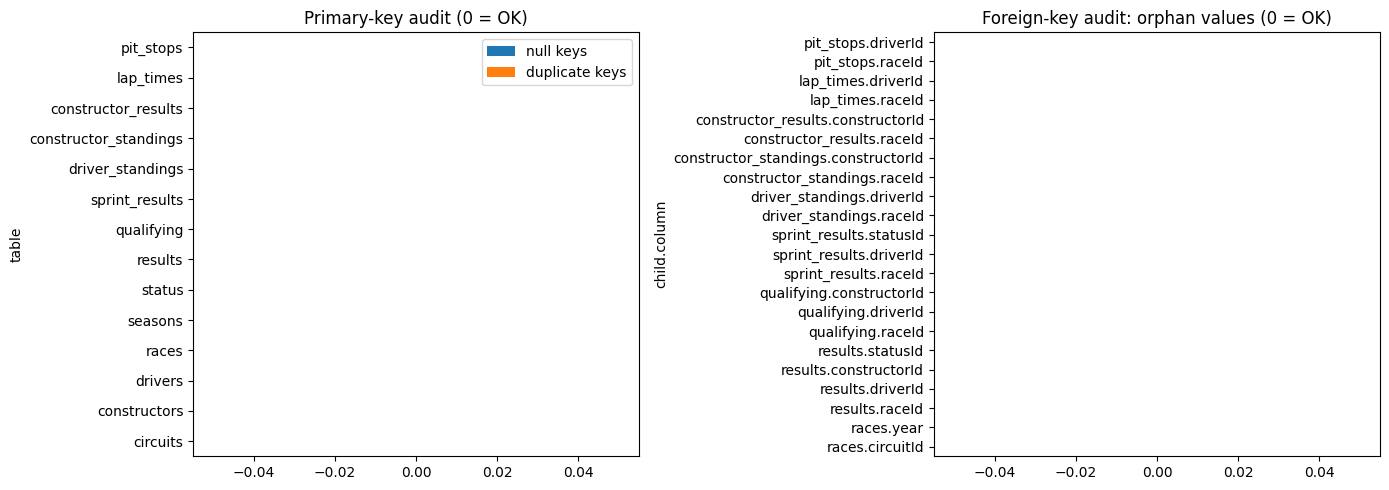

All primary keys are unique & non-null and all foreign keys reconcile.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pk_report.set_index('table')[['null keys', 'duplicate keys']].plot.barh(ax=axes[0])
axes[0].set_title('Primary-key audit (0 = OK)')
fk_report.set_index('child.column')['orphans (not found in parent)'].plot.barh(ax=axes[1], color='green')
axes[1].set_title('Foreign-key audit: orphan values (0 = OK)')
plt.tight_layout()
save('audit_keys')
plt.show()

assert pk_report[['null keys', 'duplicate keys']].sum().sum() == 0, 'primary key problem'
assert fk_report['orphans (not found in parent)'].sum() == 0, 'foreign key problem'
print('All primary keys are unique & non-null and all foreign keys reconcile.')

### 3.3 Grain: one row per (raceId, driverId)
`resultId` is unique, but a driver can still have **two result rows in the same race**. In the 1950s drivers shared cars (a driver could take over a team-mate's car mid-race), so the same driver appears with two cars.

**Rule:** keep the row with the **best (lowest) `positionOrder`** for that driver in that race.

**Why:** our question is *"did this driver finish on the podium in this race?"*. If any of the cars the driver drove reached the podium, the official result credits the driver with that podium (points were shared), so the best row is the correct answer for the target. It is also a simple, deterministic rule. These duplicates are all before 1979, so they do not touch the 2003–2024 modeling data at all — but the rule is still needed for the data-engineering questions that use all years.

In [14]:
res = clean['results'].merge(clean['races'][['raceId', 'year']], on='raceId')
dups = res[res.duplicated(['raceId', 'driverId'], keep=False)].sort_values(['raceId', 'driverId'])
print('Rows involved in duplicates:', len(dups), '| extra rows to remove:', res.duplicated(['raceId', 'driverId']).sum())
print('Years with duplicates:', sorted(dups.year.unique()))
display(dups[['raceId', 'year', 'driverId', 'constructorId', 'grid', 'positionOrder', 'laps', 'points']].head(8))

rows_before = len(res)
res = (res.sort_values(['raceId', 'driverId', 'positionOrder'])
          .drop_duplicates(['raceId', 'driverId'], keep='first')
          .reset_index(drop=True))
res['podium'] = (res['positionOrder'] <= 3).astype(int)
assert not res.duplicated(['raceId', 'driverId']).any()
assert not clean['qualifying'].duplicated(['raceId', 'driverId']).any()
print(f'results rows: {rows_before} -> {len(res)}  (raceId, driverId) is now unique')

Rows involved in duplicates: 176 | extra rows to remove: 91
Years with duplicates: [np.int64(1950), np.int64(1951), np.int64(1952), np.int64(1953), np.int64(1954), np.int64(1955), np.int64(1956), np.int64(1957), np.int64(1958), np.int64(1960), np.int64(1961), np.int64(1962), np.int64(1964), np.int64(1978)]


,raceId,year,driverId,constructorId,grid,positionOrder,laps,points
13188,540,1978,229,54,0,26,0,0.0
13191,540,1978,229,57,0,29,0,0.0
17362,717,1964,373,172,1,7,102,0.0
24298,717,1964,373,172,1,12,54,0.0
17740,733,1962,465,172,0,22,0,0.0
17743,733,1962,465,97,0,25,0,0.0
17961,742,1961,475,102,20,19,56,0.0
17963,742,1961,475,172,5,21,44,0.0


results rows: 26759 -> 26668  (raceId, driverId) is now unique


## 4. EDA after cleaning — impact of the cleaning

In [15]:
impact = pd.DataFrame({
    'before cleaning': [int(sum((df == SENTINEL).sum().sum() for df in raw.values())),
                        int(sum((df.dtypes == object).sum() for df in raw.values())),
                        len(raw['results']), raw['circuits'].country.nunique(), raw['drivers'].nationality.nunique()],
    'after cleaning': [int(sum((df == SENTINEL).sum().sum() for df in clean.values())),
                       int(sum((df.dtypes == object).sum() for df in clean.values())),
                       len(res), clean['circuits'].country.nunique(), clean['drivers'].nationality.nunique()]},
    index=['\\N sentinel cells', 'text (object) columns', 'results rows (driver-race)', 'distinct circuit countries',
           'distinct nationalities'])
impact

,before cleaning,after cleaning
\N sentinel cells,160076,0
text (object) columns,57,40
results rows (driver-race),26759,26668
distinct circuit countries,35,34
distinct nationalities,43,42


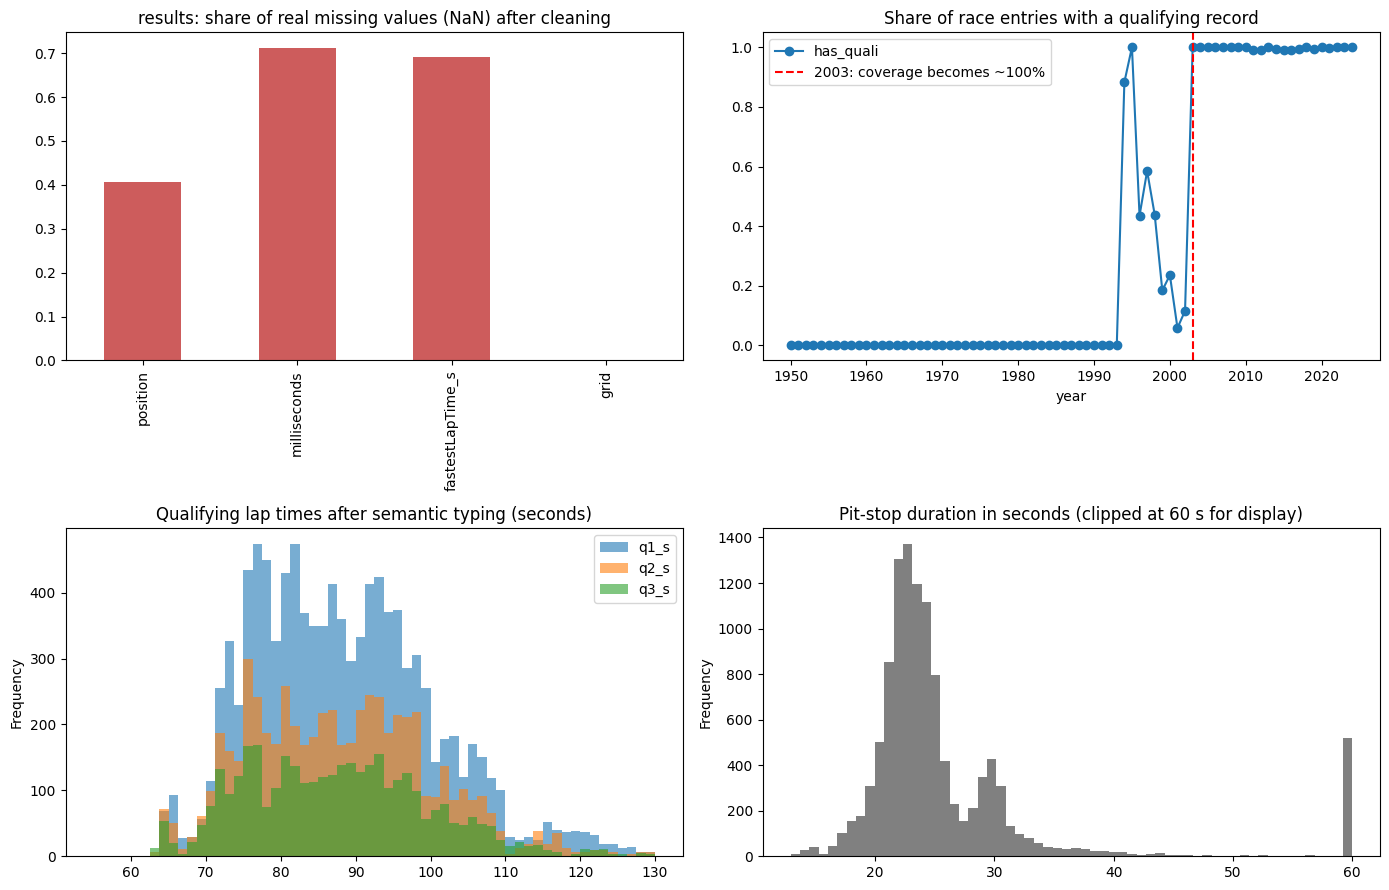

In [16]:
races_c = clean['races']
qual = clean['qualifying']
res_q = res.merge(qual[['raceId', 'driverId']].assign(has_quali=1), on=['raceId', 'driverId'], how='left')
quali_coverage = res_q.groupby('year').has_quali.apply(lambda s: s.notna().mean())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
res[['position', 'milliseconds', 'fastestLapTime_s', 'grid']].isna().mean().plot.bar(ax=axes[0, 0], color='indianred')
axes[0, 0].set_title('results: share of real missing values (NaN) after cleaning')

quali_coverage.plot(ax=axes[0, 1], marker='o')
axes[0, 1].axvline(2003, color='red', ls='--', label='2003: coverage becomes ~100%')
axes[0, 1].set_title('Share of race entries with a qualifying record'); axes[0, 1].legend()

clean['qualifying'][['q1_s', 'q2_s', 'q3_s']].plot.hist(bins=60, alpha=0.6, ax=axes[1, 0], range=(55, 130))
axes[1, 0].set_title('Qualifying lap times after semantic typing (seconds)')

clean['pit_stops'].duration_s.clip(upper=60).plot.hist(bins=60, ax=axes[1, 1], color='gray')
axes[1, 1].set_title('Pit-stop duration in seconds (clipped at 60 s for display)')
plt.tight_layout()
save('eda_after_cleaning')
plt.show()

**Impact of the cleaning**
- All `\N` sentinels are gone; the numeric columns are now real numbers and the remaining missing values are true `NaN`s that we can count and handle.
- Durations are now numbers in seconds (qualifying laps ~60–130 s, pit stops ~20–30 s, with a few red-flag stops > 60 s), and dates are real dates.
- Duplicate driver-race rows were removed (the table now has the right grain) and two label inconsistencies were fixed.
- **Qualifying coverage drift:** the dataset only has qualifying records from 1994, and between 1996 and 2002 most of them are missing. From **2003** coverage is ~100%. Because qualifying is one of our feature groups, we model on **2003–2024** (the full history is still used to compute past form).

## 5. Data-engineering questions
All three need multi-table joins (`results` + `races` + `circuits` + `qualifying` / `drivers` / `status` / `constructors`).

### Q1. Which circuits convert a front-row start into a podium most often, and does that change after the 2014 hybrid era?
- **Join path:** `results` → `races` (year, circuit) → `circuits` (name) + `qualifying` (qualifying position).
- **Grain:** one row per driver-race; a *front-row start* is `grid` 1 or 2.
- **Qualifying vs grid:** qualifying position is where the driver qualified; `grid` is where they actually started (penalties can move them back). We compute the conversion using both.
- **Missingness / window:** qualifying records are only complete from 2003, so we compare **2003–2013 (pre-hybrid)** with **2014–2024 (hybrid)**. Only circuits with at least 8 front-row starts (≈4 races) in **both** eras are ranked, so rates are not based on 1–2 races.
- Pre-race cutoff: grid and qualifying are both known before the race; the podium is the outcome.

In [17]:
circuits = clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})
base = (res.merge(races_c[['raceId', 'circuitId']], on='raceId')
           .merge(circuits, on='circuitId')
           .merge(qual[['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
                  on=['raceId', 'driverId'], how='left'))

ERAS = ['2003-2013 (pre-hybrid)', '2014-2024 (hybrid)']
q1 = base[base.year >= 2003].copy()
q1['era'] = np.where(q1.year >= 2014, ERAS[1], ERAS[0])

def front_row_conversion(frame, col, min_starts=8):
    fr = frame[frame[col].isin([1, 2])]
    t = fr.groupby(['circuit', 'era']).podium.agg(['mean', 'size']).unstack('era')
    return t['mean'][ERAS].where(t['size'][ERAS] >= min_starts).dropna(), t['size'][ERAS]

conv_grid, n_grid = front_row_conversion(q1, 'grid')
ranks = conv_grid.rank(ascending=False, method='min').astype(int).add_suffix(' rank')
q1_table = conv_grid.round(3).join(ranks).sort_values(ERAS[1], ascending=False)
q1_table

era,2003-2013 (pre-hybrid),2014-2024 (hybrid),2003-2013 (pre-hybrid) rank,2014-2024 (hybrid) rank
circuit,,,,
Suzuka Circuit,0.722,0.889,4,1
Yas Marina Circuit,0.600,0.864,12,2
Circuit de Monaco,0.773,0.850,1,3
Circuit de Barcelona-Catalunya,0.682,0.818,7,4
Circuit de Spa-Francorchamps,0.722,0.818,4,4
Autódromo José Carlos Pace,0.591,0.789,14,6
Shanghai International Circuit,0.650,0.786,9,7
Circuit Gilles Villeneuve,0.600,0.778,12,8
Silverstone Circuit,0.727,0.750,3,9


In [18]:
rho = conv_grid[ERAS[0]].corr(conv_grid[ERAS[1]], method='spearman')
print(f'Circuits ranked in both eras: {len(conv_grid)}')
print(f'Spearman rank correlation between eras: {rho:.2f}')
print('\nTop 5 pre-hybrid :', list(conv_grid[ERAS[0]].sort_values(ascending=False).index[:5]))
print('Top 5 hybrid     :', list(conv_grid[ERAS[1]].sort_values(ascending=False).index[:5]))

fr_q = q1[q1.quali_pos.isin([1, 2])]
moved = fr_q[~fr_q.grid.isin([1, 2])]
summary_q1 = pd.DataFrame({
    'front row by GRID': q1[q1.grid.isin([1, 2])].groupby('era').podium.mean(),
    'front row by QUALIFYING': fr_q.groupby('era').podium.mean()}).round(3)
print(f'\nFront-row qualifiers who did NOT start on the front row (penalties etc.): {len(moved)} '
      f'-> their podium rate: {moved.podium.mean():.2f}')
summary_q1

Circuits ranked in both eras: 16
Spearman rank correlation between eras: 0.21

Top 5 pre-hybrid : ['Autodromo Nazionale di Monza', 'Circuit de Monaco', 'Silverstone Circuit', 'Circuit de Spa-Francorchamps', 'Suzuka Circuit']
Top 5 hybrid     : ['Suzuka Circuit', 'Yas Marina Circuit', 'Circuit de Monaco', 'Circuit de Barcelona-Catalunya', 'Circuit de Spa-Francorchamps']

Front-row qualifiers who did NOT start on the front row (penalties etc.): 38 -> their podium rate: 0.29


,front row by GRID,front row by QUALIFYING
era,,
2003-2013 (pre-hybrid),0.68,0.672
2014-2024 (hybrid),0.76,0.737


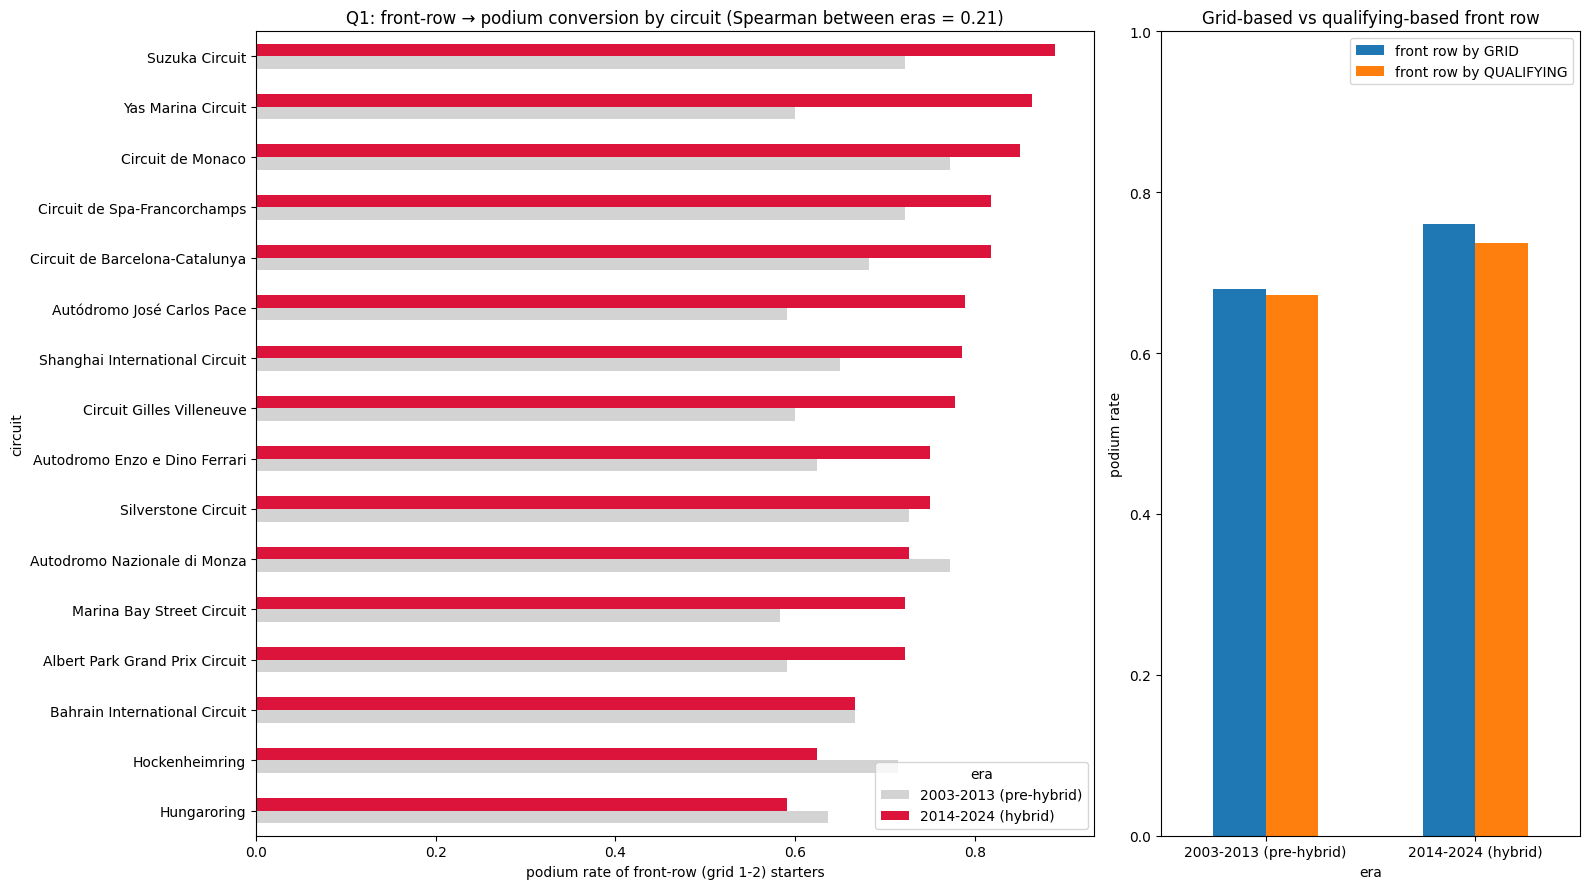

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 9), gridspec_kw={'width_ratios': [2, 1]})
conv_grid.sort_values(ERAS[1]).plot.barh(ax=axes[0], color=['lightgray', 'crimson'])
axes[0].set_xlabel('podium rate of front-row (grid 1-2) starters')
axes[0].set_title(f'Q1: front-row → podium conversion by circuit (Spearman between eras = {rho:.2f})')
summary_q1.plot.bar(ax=axes[1], rot=0)
axes[1].set_ylim(0, 1); axes[1].set_title('Grid-based vs qualifying-based front row')
axes[1].set_ylabel('podium rate')
plt.tight_layout()
save('q1_front_row')
plt.show()

**Q1 answer**

- **Most frequent converters.** 16 circuits have at least 8 front-row starts in both eras.
  - Pre-hybrid (2003–2013): **Monza and Monaco** (77%), then Silverstone (73%), Spa and Suzuka (72%).
  - Hybrid era (2014–2024): **Suzuka** (89%), **Yas Marina** (86%), **Monaco** (85%), then Barcelona and Spa (82%).
- **Does the ranking change? It is unstable.** The Spearman rank correlation between the two eras is only **≈0.21**. Examples: Yas Marina moved from 12th to 2nd, Monza fell from 1st to 11th and Hockenheim from 6th to 15th. However, each circuit's rate rests on only 8–22 starts, so much of this reshuffling can be small-sample noise. **The robust finding is that front-row conversion went up overall** in the hybrid era, from 68% to 76% using grid. This fits the hybrid era being dominated by one or two teams (Mercedes 2014–2020, Red Bull 2022–2024), whose cars rarely drop out of the top 3.
- **Qualifying vs grid.**
  - Using qualifying position instead of grid gives slightly lower conversion (67% / 74%).
  - 38 drivers qualified on the front row but did *not* start there, because of grid penalties. Only **29%** of them reached the podium.
  - So qualifying and grid are different pieces of information, and both are available before the race. We use both as features, plus their difference (`grid_penalty`).
- **Caveat.** Each circuit has only 8–22 front-row starts per era, so differences of about 10 percentage points between single circuits can be noise.

### Q2. Do drivers podium more often at a home race, after controlling for starting position?
- **Join path:** `results` → `races` → `circuits` (country) and `results` → `drivers` (nationality). A small dictionary maps nationality → country (e.g. *British → UK*).
- **Home race:** driver country == circuit country. Only drivers whose country has hosted at least one Grand Prix are used, so every driver in the comparison *could* have a home race.
- **Controlling for starting position:** home drivers might simply start further up. We split the data into **grid bins** (P1, P2–3, P4–6, P7–10, P11+) and compare home vs away **within the same bin**; then we average the within-bin differences (weighted by the number of home starts) → an "adjusted" difference.
- **Missingness / cutoff:** rows with `grid = 0` (pit lane / no grid slot) are excluded because their starting position is unknown. Grid is pre-race information.

In [20]:
NAT2COUNTRY = {'American': 'USA', 'American-Italian': 'USA', 'Argentine': 'Argentina', 'Argentine-Italian': 'Argentina',
               'Australian': 'Australia', 'Austrian': 'Austria', 'Belgian': 'Belgium', 'Brazilian': 'Brazil',
               'British': 'UK', 'Canadian': 'Canada', 'Chinese': 'China', 'Dutch': 'Netherlands',
               'East German': 'Germany', 'French': 'France', 'German': 'Germany', 'Hungarian': 'Hungary',
               'Indian': 'India', 'Italian': 'Italy', 'Japanese': 'Japan', 'Malaysian': 'Malaysia',
               'Mexican': 'Mexico', 'Monegasque': 'Monaco', 'Portuguese': 'Portugal', 'Russian': 'Russia',
               'South African': 'South Africa', 'Spanish': 'Spain', 'Swedish': 'Sweden', 'Swiss': 'Switzerland'}

home = base.merge(clean['drivers'][['driverId', 'nationality']], on='driverId')
home['driver_country'] = home['nationality'].map(NAT2COUNTRY)
print('Nationalities without a home circuit (excluded):',
      sorted(set(home.nationality) - set(NAT2COUNTRY)))
home = home[home.driver_country.notna() & (home.grid > 0)].copy()
home['is_home'] = home.driver_country == home.country
home['grid_bin'] = pd.cut(home.grid, [0, 1, 3, 6, 10, 100], labels=['P1', 'P2-3', 'P4-6', 'P7-10', 'P11+'])

def home_effect(frame):
    t = frame.groupby(['grid_bin', 'is_home'], observed=True).podium.agg(['mean', 'size']).unstack('is_home')
    diff = t['mean'][True] - t['mean'][False]
    adjusted = (diff * t['size'][True]).sum() / t['size'][True].sum()
    raw_diff = frame[frame.is_home].podium.mean() - frame[~frame.is_home].podium.mean()
    return t, raw_diff, adjusted

q2_tab, raw_diff, adj_diff = home_effect(home)
_, raw_diff_03, adj_diff_03 = home_effect(home[home.year >= 2003])
display(q2_tab.round(3))
print('Average grid  — home:', round(home[home.is_home].grid.mean(), 2), '| away:', round(home[~home.is_home].grid.mean(), 2))
q2_summary = pd.DataFrame({'raw difference (home - away)': [raw_diff, raw_diff_03],
                           'grid-adjusted difference': [adj_diff, adj_diff_03],
                           'home starts': [home.is_home.sum(), home[home.year >= 2003].is_home.sum()]},
                          index=['1950-2024', '2003-2024']).round(3)
q2_summary

Nationalities without a home circuit (excluded): ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']


mean          size      
is_home   False  True   False True 
grid_bin                           
P1        0.654  0.576    941    92
P2-3      0.514  0.535   1816   172
P4-6      0.260  0.245   2706   261
P7-10     0.090  0.088   3689   387
P11+      0.016  0.016  11219  1411

Average grid  — home: 13.41 | away: 11.8


,raw difference (home - away),grid-adjusted difference,home starts
1950-2024,-0.021,-0.003,2323
2003-2024,0.001,-0.019,364


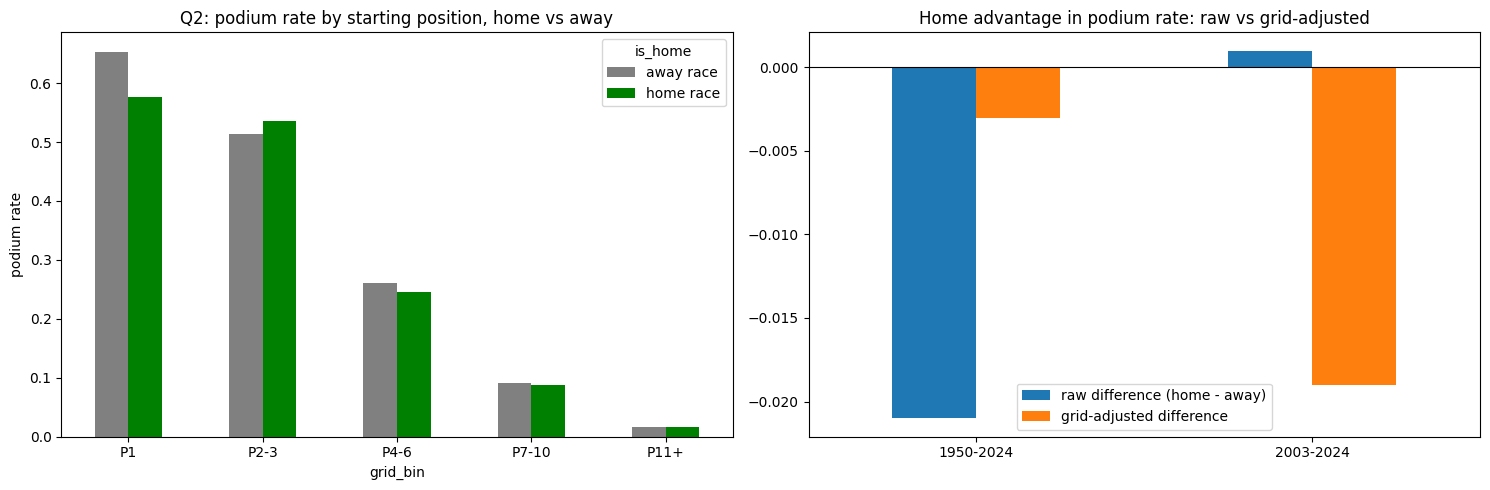

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
q2_tab['mean'].rename(columns={True: 'home race', False: 'away race'}).plot.bar(ax=axes[0], rot=0, color=['gray', 'green'])
axes[0].set_ylabel('podium rate'); axes[0].set_title('Q2: podium rate by starting position, home vs away')
q2_summary[['raw difference (home - away)', 'grid-adjusted difference']].plot.bar(ax=axes[1], rot=0)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_title('Home advantage in podium rate: raw vs grid-adjusted')
plt.tight_layout()
save('q2_home')
plt.show()

**Q2 answer**

- **Raw comparison:** over 1950–2024, drivers at home actually podium slightly *less* often: **−2.1 percentage points**. The reason is that home drivers start further back on average (mean grid **13.4 vs 11.8**). Many local drivers only entered their home Grand Prix, often in weaker cars.
- **Controlling for starting position:** inside each grid bin the home and away podium rates are almost identical (P2–3: 53.5% vs 51.4%; P4–6: 24.5% vs 26.0%; P7–10: 8.8% vs 9.0%; P11+: 1.6% vs 1.6%). The only visible gap is from pole (P1), where home drivers did *worse* (57.6% vs 65.4%), but that bin has only 92 home starts, so it is a small sample. The home groups per bin have 92–1,411 starts, against 941–11,219 away. The grid-adjusted difference is **≈ −0.3 percentage points**, essentially zero. For 2003–2024 only (364 home starts) the adjusted difference is −1.9 points, which is also not a positive home effect.
- **Answer:** no. Once starting position is accounted for, there is **no evidence that drivers podium more often at home**. For this reason we did not add a "home race" feature to the model.

### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?
- **Join path:** `results` → `status` (reason the race ended) → `constructors` (team name) → `races` (year).
- **Mechanical retirement:** the status names a **car component failure** (engine, gearbox, hydraulics, brakes, power unit, ERS, …).
  **Excluded:** crashes / driver errors (`Accident`, `Collision`, `Spun off`, `Collision damage`, `Damage`, `Debris`, broken wings),
  regulation decisions (`Disqualified`, `Excluded`, `Underweight`, `107% Rule`), and unclear/non-component reasons (`Retired`, `Withdrew`, `Illness`, `Out of fuel`, tyres/punctures, wheel nut — these are usually debris or pit-stop errors, not a car component failing).
- **Grain:** one row per car start. **Rate = mechanical retirements / race starts** (starts exclude `Withdrew`, `Did not qualify`, `Did not prequalify`, `107% Rule`).
- Only constructors with at least 30 starts in an era are ranked (to avoid rates from very few races).
- This is a retrospective question (status is post-race), so the pre-race cutoff does not apply here; it is **not** used as a model feature.

In [22]:
MECHANICAL = ['Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
              'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Driveshaft', 'Fuel pressure', 'Water pressure',
              'Throttle', 'Steering', 'Technical', 'Electronics', 'Exhaust', 'Oil leak', 'Water leak', 'Fuel pump',
              'Track rod', 'Oil pressure', 'Engine fire', 'Engine misfire', 'Pneumatics', 'Wheel bearing',
              'Fuel system', 'Oil line', 'Power loss', 'Vibrations', 'Drivetrain', 'Ignition', 'Battery', 'Halfshaft',
              'Crankshaft', 'Alternator', 'Oil pump', 'Fuel leak', 'Injection', 'Distributor', 'Turbo', 'CV joint',
              'Water pump', 'Spark plugs', 'Fuel pipe', 'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger',
              'Power Unit', 'ERS', 'Cooling system', 'Brake duct', 'Heat shield fire', 'Launch control', 'Fuel',
              'Handling', 'Seat', 'Driver Seat', 'Undertray']
NON_STARTS = ['Withdrew', 'Did not qualify', 'Did not prequalify', '107% Rule']

q3 = (res[res.year >= 2014]
      .merge(clean['status'], on='statusId')
      .merge(clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'}), on='constructorId'))
q3 = q3[~q3.status.isin(NON_STARTS)].copy()
q3['mechanical'] = q3.status.isin(MECHANICAL).astype(int)
q3['period'] = np.where(q3.year <= 2021, '2014-2021', '2022-2024')

print('Generic "Retired" (excluded, reason unknown) per start:', q3.groupby('period').apply(lambda g: round((g.status == 'Retired').mean(), 3)).to_dict())
print('Status values counted as mechanical in 2014-2024:')
print(q3[q3.mechanical == 1].status.value_counts().head(15).to_string())

q3_rates = (q3.groupby(['period', 'constructor'])
              .agg(starts=('mechanical', 'size'), mech_retirements=('mechanical', 'sum'), rate=('mechanical', 'mean'))
              .query('starts >= 30').reset_index())
for p in ['2014-2021', '2022-2024']:
    print(f'\nTop 5 mechanical-retirement rate {p}:')
    print(q3_rates[q3_rates.period == p].sort_values('rate', ascending=False).head(5)[['constructor', 'starts', 'mech_retirements', 'rate']].round(3).to_string(index=False))

Generic "Retired" (excluded, reason unknown) per start: {'2014-2021': 0.012, '2022-2024': 0.009}
Status values counted as mechanical in 2014-2024:
status
Engine            81
Brakes            49
Power Unit        42
Gearbox           42
Suspension        25
Hydraulics        15
Electrical        14
Power loss        13
Oil leak          10
Overheating        8
Mechanical         7
Water pressure     7
Turbo              6
ERS                5
Battery            5

Top 5 mechanical-retirement rate 2014-2021:
constructor  starts  mech_retirements  rate
   Caterham      34                 8 0.235
   Lotus F1      75                13 0.173
 Toro Rosso     242                39 0.161
    McLaren     318                44 0.138
    Renault     200                27 0.135

Top 5 mechanical-retirement rate 2022-2024:
   constructor  starts  mech_retirements  rate
    Alfa Romeo      88                11 0.125
Alpine F1 Team     136                15 0.110
    AlphaTauri      88              

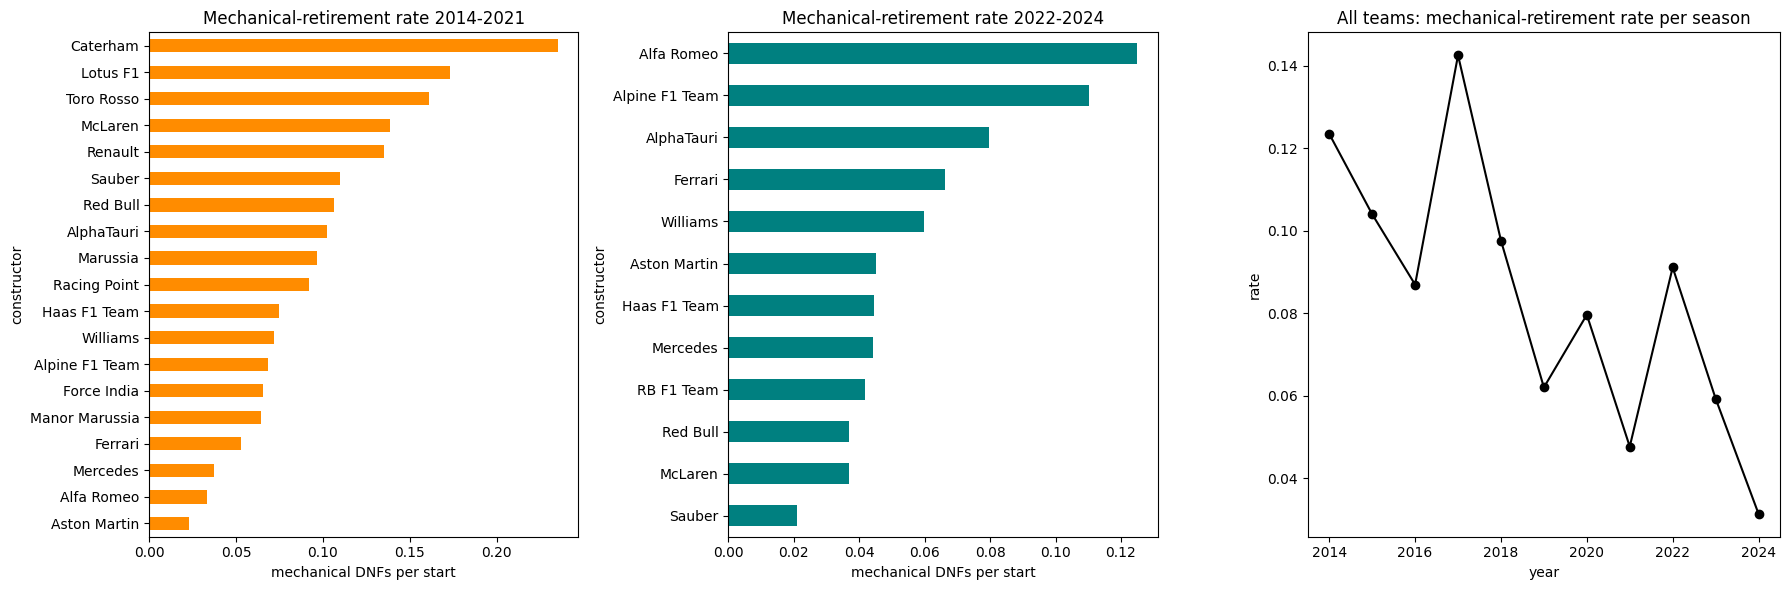

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), gridspec_kw={'width_ratios': [1, 1, 1.1]})
for ax, p, c in zip(axes[:2], ['2014-2021', '2022-2024'], ['darkorange', 'teal']):
    q3_rates[q3_rates.period == p].sort_values('rate').plot.barh(x='constructor', y='rate', ax=ax, color=c, legend=False)
    ax.set_title(f'Mechanical-retirement rate {p}'); ax.set_xlabel('mechanical DNFs per start')
q3.groupby('year').mechanical.mean().plot(ax=axes[2], marker='o', color='black')
axes[2].set_title('All teams: mechanical-retirement rate per season'); axes[2].set_ylabel('rate')
plt.tight_layout()
save('q3_mechanical')
plt.show()

**Q3 answer**

- **2014–2021, highest mechanical-retirement rates:** **Caterham 23.5%** (only 34 starts, 2014), **Lotus F1 17.3%**, **Toro Rosso 16.1%**, **McLaren 13.8%** (the McLaren-Honda years 2015–2017) and **Renault 13.5%**.
- **2022–2024:** **Alfa Romeo 12.5%**, **Alpine 11.0%**, **AlphaTauri 8.0%**, **Ferrari 6.6%** and **Williams 6.0%**.
- **Check on the excluded generic `Retired` label:** it covers only ≈1% of starts in both periods (1.2% vs 0.9%), so excluding it does not create the trend below.
- **Trend:** overall reliability improved. The all-team mechanical retirement rate per season (right plot) is clearly lower in 2022–2024 than in the early hybrid years (2014–2015), so even the "worst" teams of 2022–2024 have lower rates than the worst teams of 2014–2021.
- **Caveats:**
  - Teams that were renamed (Toro Rosso → AlphaTauri → RB, Renault → Alpine, Sauber → Alfa Romeo) have different `constructorId`s, so they are counted separately.
  - The status labels are coarse. A generic `Retired` may hide some component failures, and we excluded it on purpose.
  - The 2022–2024 period has only 3 seasons.

## 6. Feature engineering & selection (leakage-safe)

**Prediction cutoff: after qualifying, before the race.** A feature is allowed only if it is known at that moment.

| Allowed (pre-race) | NOT allowed (known only after the race → leakage) |
|---|---|
| grid position, qualifying position & times | `positionOrder`, `position`, `points`, `laps`, `time`, `milliseconds` of the current race |
| results of **previous** races (form) | `statusId` (finished / retired) of the current race |
| championship standings **before** the race (after the previous round) | fastest lap / rank of the current race, pit stops, lap times of the current race |
| | `driver_standings` / `constructor_standings` of the current `raceId` (they include this race's points) |

**Feature groups** (chosen from the EDA hypothesis: *starting position + current car/driver strength decide podiums*):

| Group | Feature | Meaning |
|---|---|---|
| grid | `grid` | starting position (pit-lane start = back of the grid) |
| grid | `grid_penalty` | `grid - quali_position` (positive = moved back by penalties) |
| qualifying | `quali_position` | qualifying classification |
| qualifying | `quali_gap_pct` | % slower than pole in qualifying (best of Q1/Q2/Q3) — pure pace |
| form | `drv_podium_rate_last5` | share of podiums in the driver's previous 5 races |
| form | `drv_avg_finish_last5` | average finishing position in the previous 5 races |
| form | `con_podium_rate_last5` | share of the team's previous 5 races with a podium |
| form | `drv_races_before` | experience: number of previous starts |
| standings | `drv_standing_before`, `drv_points_share` | championship position and points ÷ leader's points **before** this race |
| standings | `con_standing_before`, `con_points_share` | the same for the constructor |

Points are used as a **share of the leader's points** because the points system changed (10-8-6 → 25-18-15) during 2003–2024, so raw points are not comparable across seasons.

In [24]:
df = (res[['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'podium', 'year']]
      .merge(races_c[['raceId', 'round', 'date', 'circuitId']], on='raceId')
      .sort_values(['date', 'raceId', 'positionOrder']).reset_index(drop=True))

# --- grid group ---
field_size = df.groupby('raceId').driverId.transform('count')
df['grid'] = np.where(df.grid == 0, field_size, df.grid)          # pit-lane start = back of the grid

# --- qualifying group ---
q = qual[['raceId', 'driverId', 'position', 'q1_s', 'q2_s', 'q3_s']].copy()
q['best_q_s'] = q[['q1_s', 'q2_s', 'q3_s']].min(axis=1)
q['quali_gap_pct'] = 100 * (q.best_q_s / q.groupby('raceId').best_q_s.transform('min') - 1)
q = q.rename(columns={'position': 'quali_position'})[['raceId', 'driverId', 'quali_position', 'quali_gap_pct']]
df = df.merge(q, on=['raceId', 'driverId'], how='left')
df['grid_penalty'] = df.grid - df.quali_position

# --- form group: ONLY past races (shift(1) excludes the current race) ---
def add_form_features(frame):
    frame = frame.sort_values(['date', 'raceId']).copy()
    g = frame.groupby('driverId')
    frame['drv_podium_rate_last5'] = g.podium.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    frame['drv_avg_finish_last5'] = g.positionOrder.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    frame['drv_races_before'] = g.cumcount()
    team = (frame.groupby(['constructorId', 'raceId', 'date']).podium.max().reset_index()
                 .sort_values('date'))
    team['con_podium_rate_last5'] = (team.groupby('constructorId').podium
                                     .transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean()))
    return frame.merge(team[['constructorId', 'raceId', 'con_podium_rate_last5']], on=['constructorId', 'raceId'], how='left')

df = add_form_features(df)

# --- standings group: standings after the PREVIOUS round of the same season ---
def standings_before(table, key, prefix):
    s = table.merge(races_c[['raceId', 'year', 'round']], on='raceId')
    s['round'] = s['round'] + 1                                     # known before the next round
    s[f'{prefix}_points_share'] = s.points / s.groupby('raceId').points.transform('max')
    s = s.rename(columns={'position': f'{prefix}_standing_before'})
    return s[['year', 'round', key, f'{prefix}_standing_before', f'{prefix}_points_share']]

df = df.merge(standings_before(clean['driver_standings'], 'driverId', 'drv'), on=['year', 'round', 'driverId'], how='left')
df = df.merge(standings_before(clean['constructor_standings'], 'constructorId', 'con'), on=['year', 'round', 'constructorId'], how='left')
for c in ['drv_points_share', 'con_points_share']:
    df[c] = df[c].fillna(0)                                        # no points scored before (round 1 / new driver)

FEATURE_GROUPS = {
    'grid': ['grid', 'grid_penalty'],
    'qualifying': ['quali_position', 'quali_gap_pct'],
    'form': ['drv_podium_rate_last5', 'drv_avg_finish_last5', 'con_podium_rate_last5', 'drv_races_before'],
    'standings': ['drv_standing_before', 'drv_points_share', 'con_standing_before', 'con_points_share'],
}
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]
TARGET = 'podium'

mt = df[df.year >= 2003].reset_index(drop=True)            # modeling table
assert not mt.duplicated(['raceId', 'driverId']).any()
print('Modeling table:', mt.shape, '| unique (raceId, driverId):', not mt.duplicated(['raceId', 'driverId']).any())
print('Podium rate:', round(mt[TARGET].mean(), 3))
mt[['raceId', 'year', 'round', 'driverId', 'constructorId'] + FEATURES + [TARGET]].head()

Modeling table: (8970, 21) | unique (raceId, driverId): True
Podium rate: 0.143


,raceId,year,round,driverId,constructorId,grid,grid_penalty,quali_position,quali_gap_pct,drv_podium_rate_last5,drv_avg_finish_last5,con_podium_rate_last5,drv_races_before,drv_standing_before,drv_points_share,con_standing_before,con_points_share,podium
0,108,2003,1,14,1,11,0.0,11.0,2.216283,0.2,7.4,0.4,141,NaN,0.0,NaN,0.0,1
1,108,2003,1,31,3,3,0.0,3.0,1.064550,0.2,7.2,0.4,34,NaN,0.0,NaN,0.0,1
2,108,2003,1,8,1,15,0.0,15.0,2.634990,0.2,11.0,0.4,34,NaN,0.0,NaN,0.0,1
3,108,2003,1,30,6,1,0.0,1.0,0.000000,1.0,1.6,1.0,179,NaN,0.0,NaN,0.0,0
4,108,2003,1,15,4,12,0.0,12.0,2.251844,0.0,9.6,0.0,97,NaN,0.0,NaN,0.0,0


### 6.1 Leakage check of the form feature
For one driver we recompute the form feature by hand: the value used for race *k* must be the mean of races *k-5 … k-1* only (never race *k* itself).

In [25]:
d = df[df.driverId == 1].sort_values('date')                  # driverId 1 = Lewis Hamilton
manual = [d.podium.iloc[max(0, k - 5):k].mean() if k > 0 else np.nan for k in range(len(d))]
assert np.allclose(d.drv_podium_rate_last5.values, manual, equal_nan=True)
print('Form feature uses only past races ✔')
d[['date', 'positionOrder', 'podium', 'drv_podium_rate_last5', 'drv_avg_finish_last5']].head(7)

Form feature uses only past races ✔


,date,positionOrder,podium,drv_podium_rate_last5,drv_avg_finish_last5
19152,2007-03-18,3,1,NaN,NaN
19173,2007-04-08,2,1,1.0,3.000000
19195,2007-04-15,2,1,1.0,2.500000
19217,2007-05-13,2,1,1.0,2.333333
19239,2007-05-27,2,1,1.0,2.250000
19260,2007-06-10,1,1,1.0,2.200000
19282,2007-06-17,1,1,1.0,1.800000


### 6.2 Evidence for the chosen features
1. Podium rate across the range of each feature (deciles) — a feature is useful if the podium rate changes clearly across its values.
2. Correlation of every feature with the target and with each other (redundancy).
3. Missing values per feature.

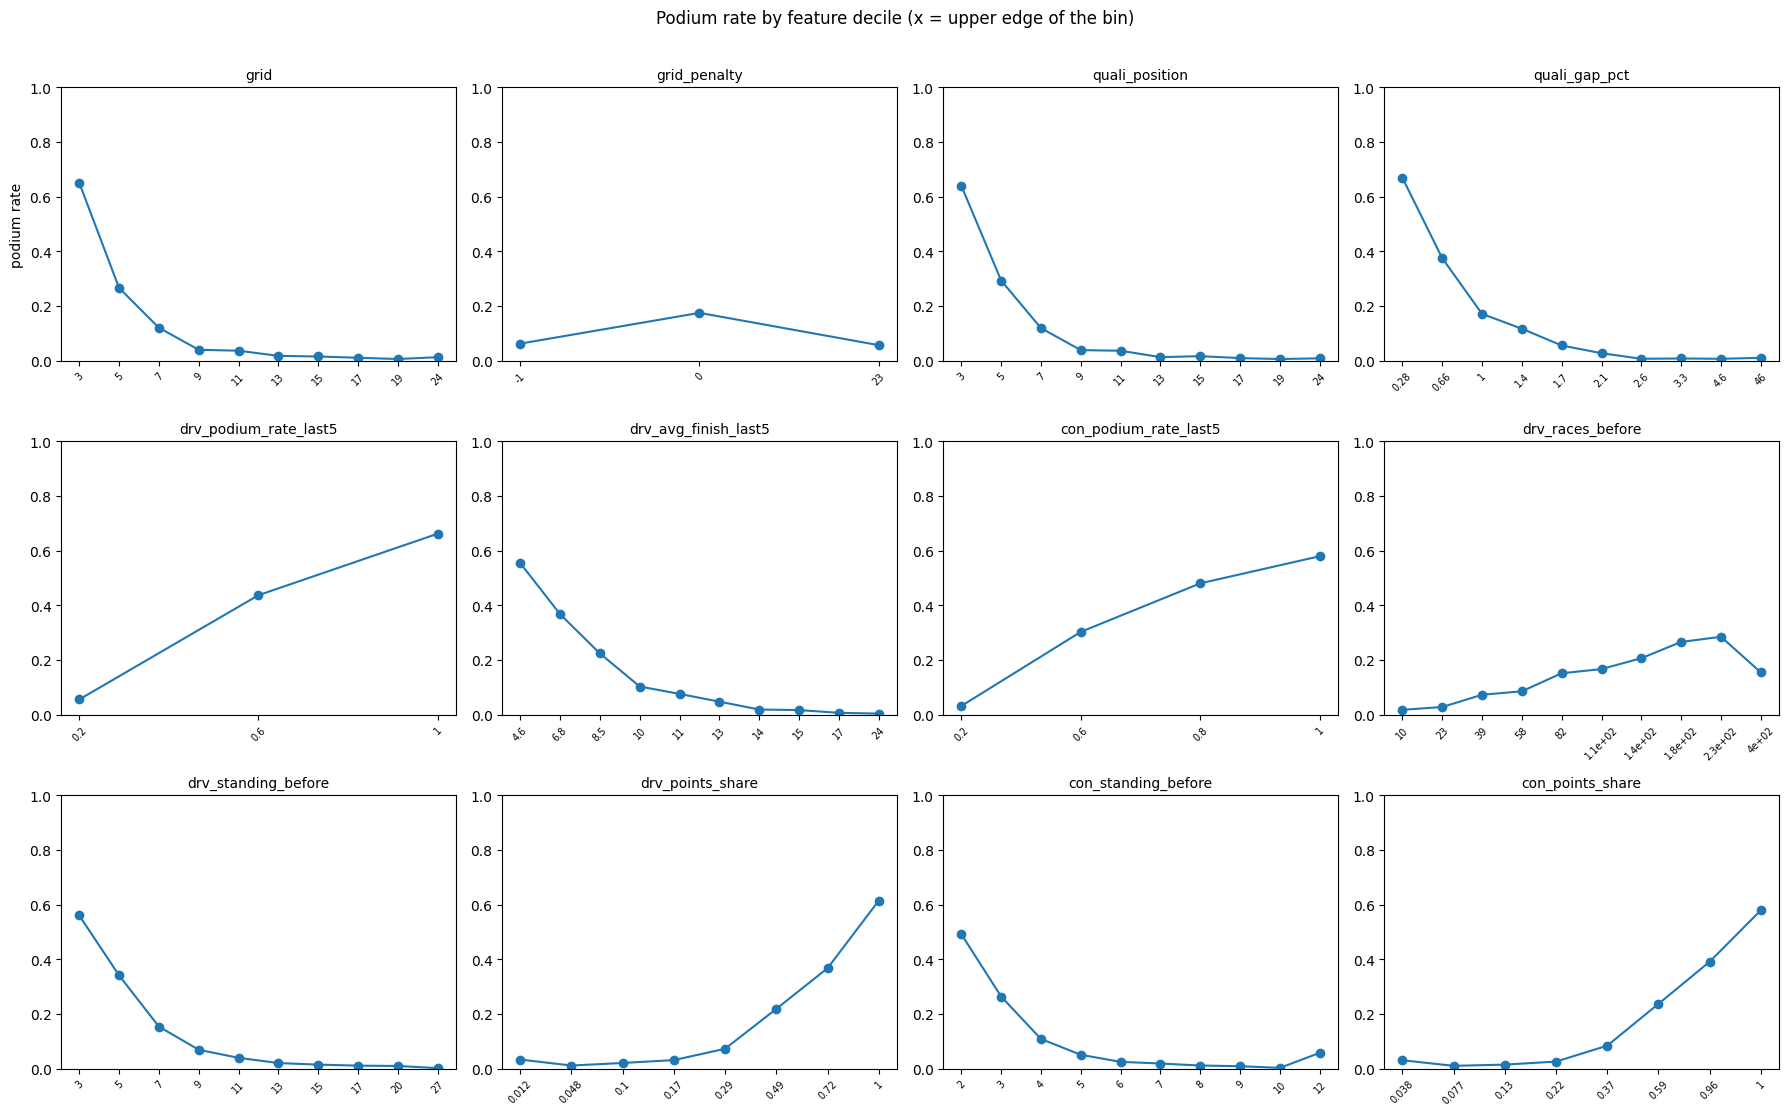

In [26]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, f in zip(axes.ravel(), FEATURES):
    bins = pd.qcut(mt[f], 10, duplicates='drop')
    rate = mt.groupby(bins, observed=True)[TARGET].mean()
    ax.plot(range(len(rate)), rate.values, marker='o')
    ax.set_xticks(range(len(rate)))
    ax.set_xticklabels([f'{iv.right:.2g}' for iv in rate.index], rotation=45, fontsize=7)
    ax.set_title(f, fontsize=10); ax.set_ylim(0, 1)
axes[0, 0].set_ylabel('podium rate')
plt.suptitle('Podium rate by feature decile (x = upper edge of the bin)', y=1.01)
plt.tight_layout()
save('feature_effects')
plt.show()

quali_position          -0.501
grid                    -0.497
quali_gap_pct           -0.482
drv_standing_before     -0.479
con_standing_before     -0.451
drv_avg_finish_last5    -0.445
grid_penalty             0.074
drv_races_before         0.217
con_points_share         0.434
drv_points_share         0.438
con_podium_rate_last5    0.509
drv_podium_rate_last5    0.522


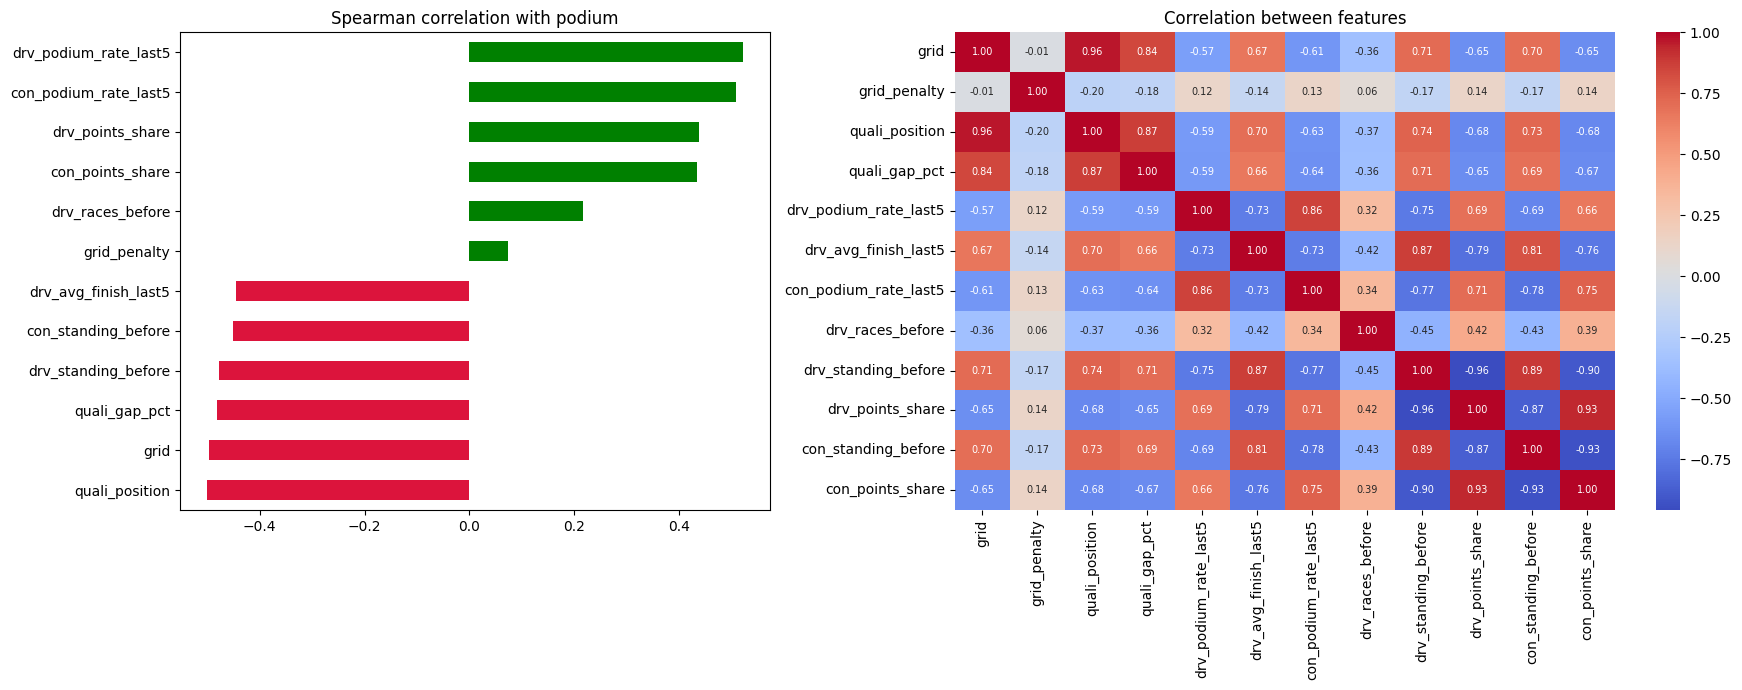

Missing share per feature (modeling table):
grid                     0.000
grid_penalty             0.003
quali_position           0.003
quali_gap_pct            0.016
drv_podium_rate_last5    0.010
drv_avg_finish_last5     0.010
con_podium_rate_last5    0.005
drv_races_before         0.000
drv_standing_before      0.068
drv_points_share         0.000
con_standing_before      0.055
con_points_share         0.000


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={'width_ratios': [1, 1.4]})
corr_target = mt[FEATURES + [TARGET]].corr(method='spearman')[TARGET].drop(TARGET).sort_values()
print(corr_target.round(3).to_string())
corr_target.plot.barh(ax=axes[0], color=np.where(corr_target > 0, 'green', 'crimson'))
axes[0].set_title('Spearman correlation with podium')
sns.heatmap(mt[FEATURES].corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1], annot_kws={'size': 7})
axes[1].set_title('Correlation between features')
plt.tight_layout()
save('feature_correlations')
plt.show()
print('Missing share per feature (modeling table):')
print(mt[FEATURES].isna().mean().round(3).to_string())

**Evidence and reasoning for each feature group** (hypothesis-driven, from the EDA):
- **Grid & qualifying:** the strongest signals. Spearman correlation with podium: `quali_position` −0.50, `grid` −0.50. The decile plot shows the podium rate falling from ~75% for the front positions to almost 0 after P8, as already seen in the raw EDA. `quali_gap_pct` (−0.48) adds **pace** information: P1 and P2 can be 0.02% or 1% apart. `grid_penalty` is almost always 0 (correlation 0.07), but Q1 showed that drivers moved back by penalties podium much less often, so we keep it.
- **Form:** `drv_podium_rate_last5` (+0.52) and `con_podium_rate_last5` (+0.51) are among the strongest single features, because recent results show how strong the car and driver currently are. `drv_races_before` (experience, +0.22) is weaker.
- **Standings:** standing and points share before the race (±0.44–0.48) describe the same "car strength" idea over the whole season so far.
- **Redundancy:** the heatmap shows that grid and quali_position are almost the same (0.9+), and that form and standings are strongly correlated with each other. That is expected, because all of them measure "how fast is this car/driver". The **ablation** in Section 11 checks whether each group still adds something after training.
- **Missing values** are small: standings 5–7% (first race of a season or new drivers), form ≈1% (debutants), qualifying <2%. These are handled by median imputation inside the pipeline.
- Every feature is computed from the **qualifying of this race** or from **previous races only**, so none of them uses information from after the start (see the leakage table and the check in 6.1).

## 7. Dataset split — train / validation / test

**Split by season (time-based), not random:**
- **Train: 2003–2017**, **Validation: 2018–2021**, **Test (unseen): 2022–2024**.

Why:
- The real use case is predicting **future** races from past ones; a random split would put races from the same weekend/season in both train and test and over-estimate performance.
- The form and standings features are built from the past, so a time split keeps everything chronological.
- Validation is used for **every choice** (hyperparameters, probability threshold, final model). The test seasons are only **reported** (model comparison, ablation, XAI); they are never used to choose anything.
- The test set is also a new regulation era (2022 cars), which is a realistic, harder test.

In [28]:
train = mt[mt.year <= 2017]
val = mt[(mt.year >= 2018) & (mt.year <= 2021)]
test = mt[mt.year >= 2022]
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

split_info = pd.DataFrame({'seasons': ['2003-2017', '2018-2021', '2022-2024'],
                           'rows': [len(train), len(val), len(test)],
                           'races': [train.raceId.nunique(), val.raceId.nunique(), test.raceId.nunique()],
                           'podium rate': [y_train.mean(), y_val.mean(), y_test.mean()]},
                          index=['train', 'validation', 'test']).round(3)
split_info

,seasons,rows,races,podium rate
train,2003-2017,5991,279,0.14
validation,2018-2021,1620,81,0.15
test,2022-2024,1359,68,0.15


## 8. Pre-processing

Steps (fitted on the **training set only**, then applied to validation/test):
1. **Missing values → median** (`SimpleImputer(strategy='median')`). Missing values are mostly drivers without previous races (form), round 1 of a season (standings) or the few entries without a qualifying record. The median is robust to the outliers in `quali_gap_pct`.
2. **Standardisation** (`StandardScaler`) for Logistic Regression and the Neural Network (they are sensitive to feature scale). The Random Forest only gets the imputer — trees split on thresholds, so scaling does not change them.

Below we show the effect of the steps on the data distribution / range / values.

In [29]:
def make_prep(scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return Pipeline(steps)

prep = make_prep().fit(X_train)
X_train_t = pd.DataFrame(prep.transform(X_train), columns=FEATURES)
effect = pd.DataFrame({'missing before': X_train.isna().sum(), 'missing after': X_train_t.isna().sum(),
                       'mean before': X_train.mean(), 'mean after': X_train_t.mean(),
                       'std before': X_train.std(), 'std after': X_train_t.std(),
                       'min before': X_train.min(), 'max before': X_train.max(),
                       'min after': X_train_t.min(), 'max after': X_train_t.max()}).round(2)
effect

,missing before,missing after,mean before,mean after,std before,std after,min before,max before,min after,max after
grid,0,0,11.30,-0.0,6.30,1.0,1.0,24.0,-1.64,2.02
grid_penalty,21,0,0.01,0.0,1.56,1.0,-7.0,23.0,-4.49,14.73
quali_position,21,0,11.26,-0.0,6.28,1.0,1.0,24.0,-1.64,2.03
quali_gap_pct,109,0,2.42,-0.0,2.73,1.0,0.0,37.8,-0.89,13.07
drv_podium_rate_last5,70,0,0.14,0.0,0.25,1.0,0.0,1.0,-0.56,3.45
drv_avg_finish_last5,70,0,11.23,0.0,4.56,1.0,1.0,24.0,-2.26,2.82
con_podium_rate_last5,34,0,0.22,-0.0,0.33,1.0,0.0,1.0,-0.68,2.39
drv_races_before,0,0,91.66,0.0,78.71,1.0,0.0,325.0,-1.16,2.96
drv_standing_before,454,0,11.39,0.0,6.54,1.0,1.0,27.0,-1.65,2.49
drv_points_share,0,0,0.24,-0.0,0.30,1.0,0.0,1.0,-0.79,2.55


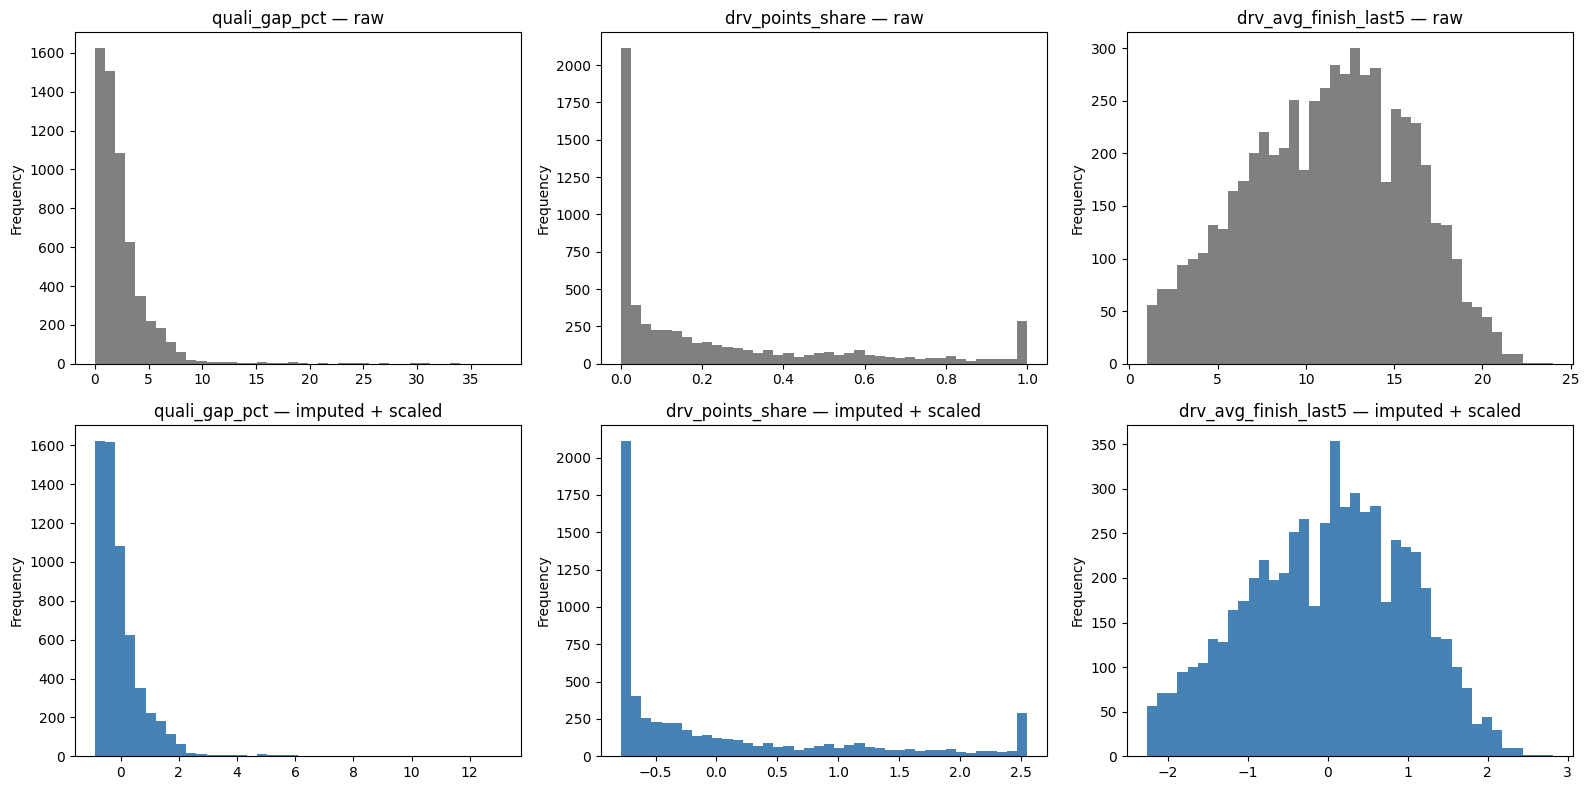

In [30]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, f in enumerate(['quali_gap_pct', 'drv_points_share', 'drv_avg_finish_last5']):
    X_train[f].plot.hist(bins=40, ax=axes[0, i], color='gray'); axes[0, i].set_title(f'{f} — raw')
    X_train_t[f].plot.hist(bins=40, ax=axes[1, i], color='steelblue'); axes[1, i].set_title(f'{f} — imputed + scaled')
plt.tight_layout()
save('preprocessing_effect')
plt.show()

**Effect:** after imputation there are no missing values; the imputed rows pile up at the median (visible spike). After scaling every feature has mean 0 and standard deviation 1 so no feature dominates the logistic regression / neural network just because of its units (e.g. `drv_races_before` goes up to ~300 while shares are between 0 and 1). The shape of each distribution does not change — scaling only shifts and stretches it.

### 8.1 Helper functions (metrics and threshold)
- **Primary metric: PR-AUC** (average precision) — the positive class is rare (~15% podiums), and PR-AUC focuses on how well the real podium finishers are ranked at the top, while ROC-AUC can look high just because there are many easy negatives.
- **Secondary metric: F1** at a probability threshold chosen on the **validation set** (the threshold that maximises validation F1) — this is the number that matters when we actually say "podium / no podium".
- Also reported: ROC-AUC, Precision and Recall. The spec table lists ROC-AUC, PR-AUC and F1; we add **Precision and Recall** as the remaining two of the "five metrics" because F1 is built from them, so they show *why* F1 is high or low.

In [31]:
def get_metrics(y, p, thr):
    pred = (p >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p),
            'F1': f1_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred)}

def best_threshold(y, p):
    thresholds = np.arange(0.05, 0.96, 0.01)
    scores = [f1_score(y, (p >= t).astype(int)) for t in thresholds]
    return float(thresholds[int(np.argmax(scores))])

def evaluate(model, name, Xtr=X_train, Xva=X_val, Xte=X_test):
    """Threshold is chosen on validation; returns rows for train / validation / test."""
    p_tr, p_va, p_te = [model.predict_proba(X)[:, 1] for X in (Xtr, Xva, Xte)]
    thr = best_threshold(y_val, p_va)
    rows = []
    for split, y, p in [('train', y_train, p_tr), ('validation', y_val, p_va), ('test', y_test, p_te)]:
        rows.append({'model': name, 'split': split, 'threshold': thr, **get_metrics(y, p, thr)})
    return pd.DataFrame(rows)

### 8.2 Pre-processing-order experiments
We keep the model fixed (Logistic Regression baseline) and change only **the order of the pipeline steps**, so any difference comes from the order.

**Experiment A — fit the imputer/scaler before vs after the split.**
- *Wrong order:* compute the median and mean/std on the **whole** modeling table (2003–2024), then split.
- *Correct order:* split first, fit on the **training** set only.

In [32]:
# Experiment A — attempt 1: preprocessing fitted on ALL data before splitting (leaky order)
prep_all = make_prep().fit(mt[FEATURES])
lr_a1 = LogisticRegression(max_iter=1000).fit(prep_all.transform(X_train), y_train)
p_val_a1 = lr_a1.predict_proba(prep_all.transform(X_val))[:, 1]
p_test_a1 = lr_a1.predict_proba(prep_all.transform(X_test))[:, 1]

In [33]:
# Experiment A — attempt 2: split first, preprocessing fitted on TRAIN only (correct order)
prep_tr = make_prep().fit(X_train)
lr_a2 = LogisticRegression(max_iter=1000).fit(prep_tr.transform(X_train), y_train)
p_val_a2 = lr_a2.predict_proba(prep_tr.transform(X_val))[:, 1]
p_test_a2 = lr_a2.predict_proba(prep_tr.transform(X_test))[:, 1]

exp_a = pd.DataFrame({
    'fit before split (all data)': {'val PR-AUC': average_precision_score(y_val, p_val_a1), 'test PR-AUC': average_precision_score(y_test, p_test_a1),
                                    'val ROC-AUC': roc_auc_score(y_val, p_val_a1), 'test ROC-AUC': roc_auc_score(y_test, p_test_a1)},
    'fit after split (train only)': {'val PR-AUC': average_precision_score(y_val, p_val_a2), 'test PR-AUC': average_precision_score(y_test, p_test_a2),
                                     'val ROC-AUC': roc_auc_score(y_val, p_val_a2), 'test ROC-AUC': roc_auc_score(y_test, p_test_a2)}}).T.round(4)
print('Training medians vs all-data medians (what leaks):')
print(pd.DataFrame({'train median': X_train.median(), 'all-data median': mt[FEATURES].median()}).round(3).T.to_string())
exp_a

Training medians vs all-data medians (what leaks):
                 grid  grid_penalty  quali_position  quali_gap_pct  drv_podium_rate_last5  drv_avg_finish_last5  con_podium_rate_last5  drv_races_before  drv_standing_before  drv_points_share  con_standing_before  con_points_share
train median     11.0           0.0            11.0          1.758                    0.0                  11.4                    0.0              68.0                 11.0             0.099                  6.0             0.128
all-data median  11.0           0.0            11.0          1.723                    0.0                  11.4                    0.0              82.0                 11.0             0.100                  6.0             0.130


,val PR-AUC,test PR-AUC,val ROC-AUC,test ROC-AUC
fit before split (all data),0.6976,0.7001,0.9309,0.9349
fit after split (train only),0.6976,0.7002,0.9309,0.9349


**Experiment B — compute the form features before vs after filtering to the modeling era (2003+).**
- *Attempt 1:* filter to 2003+ **first**, then compute the rolling form features → every driver starts 2003 with "no history" (cold start).
- *Attempt 2 (our pipeline):* compute form on the **full 1950–2024 history first**, then filter → 2003 rows already know the previous races.

Both are leakage-safe (only past races); the question is whether the order loses information.

In [34]:
# Experiment B — attempt 1: filter first, then compute form features
form_cols = FEATURE_GROUPS['form']
mt_b1 = add_form_features(df[df.year >= 2003].drop(columns=form_cols)).set_index(['raceId', 'driverId'])
mt_b1 = mt_b1.loc[list(zip(mt.raceId, mt.driverId))].reset_index()           # same row order as mt
tr_b1, va_b1 = mt_b1[mt_b1.year <= 2017], mt_b1[(mt_b1.year >= 2018) & (mt_b1.year <= 2021)]
print('Missing form values in train — filter first:', int(tr_b1[form_cols].isna().sum().sum()),
      '| full history first:', int(X_train[form_cols].isna().sum().sum()))
print('Mean drv_races_before in 2003 — filter first:', round(mt_b1[mt_b1.year == 2003].drv_races_before.mean(), 1),
      '| full history first:', round(mt[mt.year == 2003].drv_races_before.mean(), 1))

Missing form values in train — filter first: 246 | full history first: 174
Mean drv_races_before in 2003 — filter first: 7.1 | full history first: 80.0


In [35]:
# Experiment B — compare both orders with the same models
rows = []
for order, tr, va in [('filter -> form (cold start)', tr_b1, va_b1), ('form on full history -> filter', train, val)]:
    for name, model in [('LogReg', Pipeline([('prep', make_prep()), ('clf', LogisticRegression(max_iter=1000))])),
                        ('RandomForest', Pipeline([('prep', make_prep(False)), ('clf', RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=10, random_state=42, n_jobs=-1))]))]:   # RF setting selected in 9.2
        model.fit(tr[FEATURES], tr[TARGET])
        p = model.predict_proba(va[FEATURES])[:, 1]
        rows.append({'order': order, 'model': name, 'val PR-AUC': average_precision_score(va[TARGET], p),
                     'val ROC-AUC': roc_auc_score(va[TARGET], p)})
exp_b = pd.DataFrame(rows).round(4)
exp_b

,order,model,val PR-AUC,val ROC-AUC
0,filter -> form (cold start),LogReg,0.6988,0.9308
1,filter -> form (cold start),RandomForest,0.7191,0.9418
2,form on full history -> filter,LogReg,0.6976,0.9309
3,form on full history -> filter,RandomForest,0.7219,0.9418


**Experiment C — imputation before vs after scaling.**
- *Attempt 1 (our pipeline):* median-impute first, then standardise.
- *Attempt 2:* standardise first (the scaler ignores NaNs), then median-impute the scaled values.

In [36]:
# Experiment C — compare the two step orders with the baseline Logistic Regression
orders_c = {'impute -> scale': Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]),
            'scale -> impute': Pipeline([('scale', StandardScaler()), ('impute', SimpleImputer(strategy='median'))])}
rows = []
for order, pre in orders_c.items():
    m = Pipeline([('prep', pre), ('clf', LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
    Xt = pre.transform(X_train)
    rows.append({'order': order, 'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1]),
                 'test PR-AUC': average_precision_score(y_test, m.predict_proba(X_test)[:, 1]),
                 'train std of drv_standing_before after prep': Xt[:, FEATURES.index('drv_standing_before')].std()})
exp_c = pd.DataFrame(rows).round(4)
exp_c

,order,val PR-AUC,test PR-AUC,train std of drv_standing_before after prep
0,impute -> scale,0.6976,0.7002,1.0000
1,scale -> impute,0.6977,0.7000,0.9615


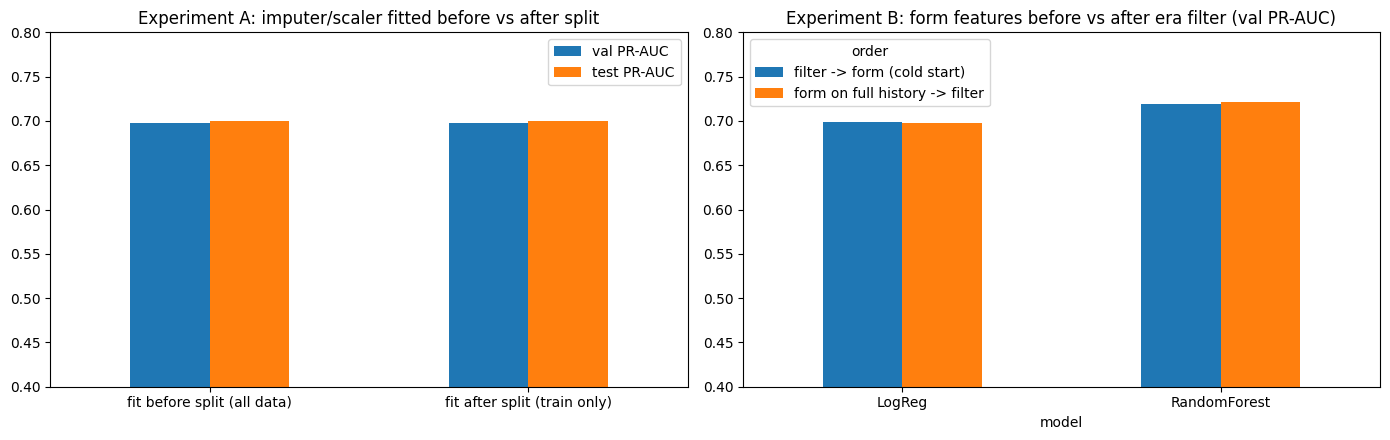

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
exp_a[['val PR-AUC', 'test PR-AUC']].plot.bar(ax=axes[0], rot=0); axes[0].set_ylim(0.4, 0.8)
axes[0].set_title('Experiment A: imputer/scaler fitted before vs after split')
exp_b.pivot(index='model', columns='order', values='val PR-AUC').plot.bar(ax=axes[1], rot=0); axes[1].set_ylim(0.4, 0.8)
axes[1].set_title('Experiment B: form features before vs after era filter (val PR-AUC)')
plt.tight_layout()
save('preprocessing_order')
plt.show()

**Results of the pre-processing-order experiments**
- **Experiment A (fit the imputer/scaler before vs after the split):** almost no difference (val PR-AUC 0.6976 in both, test 0.7001 vs 0.7002). The medians and means of the training set and of the whole table are very similar: only `drv_races_before` (68 vs 82) and `quali_gap_pct` changed noticeably (the points-share medians moved by ≤0.002). Few values are imputed, and the logistic regression barely reacts to small shifts in scaling. **We still use the correct order (fit on train only)**, because the leaky order uses statistics from the validation and test seasons, which is not available in real use. In this dataset the leak is simply small.
- **Experiment B (compute form before vs after the era filter):** computing form after the filter gives a cold start. Training then has more missing form values (246 vs 174), and in 2003 the average driver appears to have only 7 previous races instead of 80, which is wrong. Performance is about the same: LR 0.699 (cold start) vs 0.698, and RF 0.719 (cold start) vs **0.722** (full history). The cold start only affects the first one or two of the 15 training seasons, and grid/standings carry most of the signal. **We keep "full history first"**, because it produces the true values (real experience and real form in 2003). It is also what the inference function sees in real use, where the full history is always available.
- **Experiment C (impute → scale vs scale → impute):** the results are practically identical. `StandardScaler` ignores missing values when it computes the mean/std, so the two orders only differ in whether the imputed medians are included in the std, which is a tiny change with so few missing values.
- **Lesson:** in all three experiments the differences are at most about 0.003 PR-AUC, which is smaller than the seed-to-seed variation measured in 9.4 (RF std ≈ 0.004). We choose the order for **validity** (no information from validation/test seasons, true history values), not because it scored better.

## 9. Modeling

All models use **the same rows (train/val/test) and the same 12 features**, so the scores are directly comparable.

| # | Attempt | Role |
|---|---|---|
| 0 | Rule "the better the grid slot, the higher the podium chance" | sanity reference (no learning) |
| 1 | Logistic Regression | **baseline** statistical model |
| 2 | Random Forest (6 hyperparameter variants) | 2nd statistical model |
| 3 | Shallow neural network (2 architectures) | neural model |

**How they work (short):**
- **Logistic Regression:** a weighted sum of the (scaled) features passed through a sigmoid → probability. Linear decision boundary, easy to interpret. *Limitation:* cannot learn interactions/non-linear effects unless we create them (e.g. grid matters differently for strong vs weak teams).
- **Random Forest:** many decision trees, each trained on a bootstrap sample with random feature subsets; the probability is the average vote. Captures non-linear effects and interactions. *Limitations:* less transparent, probabilities can be poorly calibrated, may overfit if trees are very deep.
- **Shallow NN:** 1–2 hidden layers of ReLU neurons and a sigmoid output, trained with Adam on binary cross-entropy, early stopping on the validation loss. *Limitations:* needs scaling, results vary with the random seed, hardest to explain, and with ~6k training rows it has no real advantage over trees.

### 9.0 Reference rule (score = better grid slot, threshold chosen on validation) and 9.1 Baseline — Logistic Regression
For Logistic Regression we try 4 values of the regularisation strength `C` and keep the best **validation** PR-AUC.

In [38]:
class GridRule:
    """Not a learned model: score = -grid, so a better grid slot gives a higher 'probability'."""
    def predict_proba(self, X):
        s = 1 - (X['grid'].values - 1) / 30
        return np.column_stack([1 - s, s])

results = [evaluate(GridRule(), 'Rule: grid position')]

lr_trials = []
for C in [0.01, 0.1, 1, 10]:
    m = Pipeline([('prep', make_prep()), ('clf', LogisticRegression(C=C, max_iter=1000))]).fit(X_train, y_train)
    lr_trials.append({'C': C, 'train PR-AUC': average_precision_score(y_train, m.predict_proba(X_train)[:, 1]),
                      'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
lr_trials = pd.DataFrame(lr_trials).round(4)
best_C = lr_trials.loc[lr_trials['val PR-AUC'].idxmax(), 'C']
print('Best C (validation):', best_C)
lr_trials

Best C (validation): 1.0


,C,train PR-AUC,val PR-AUC
0,0.01,0.6692,0.6886
1,0.10,0.6786,0.6973
2,1.00,0.6788,0.6976
3,10.00,0.6786,0.6975


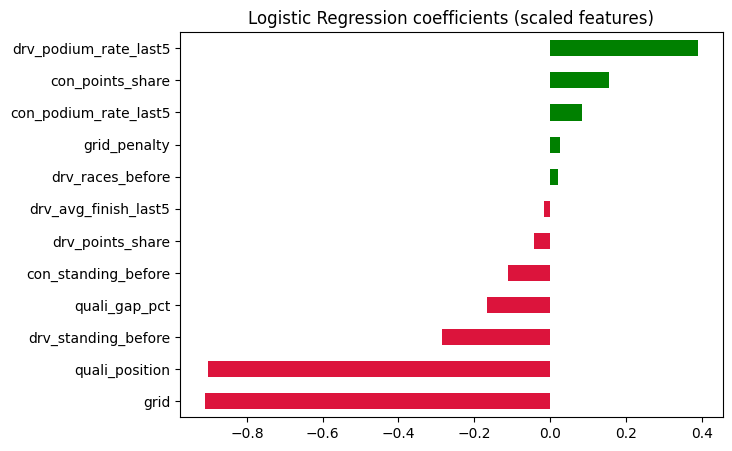

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Logistic Regression,train,0.34,0.9249,0.6788,0.6576,0.6048,0.7204
1,Logistic Regression,validation,0.34,0.9309,0.6976,0.7223,0.6461,0.8189
2,Logistic Regression,test,0.34,0.9349,0.7002,0.6667,0.6098,0.7353


In [39]:
logreg = Pipeline([('prep', make_prep()), ('clf', LogisticRegression(C=best_C, max_iter=1000))]).fit(X_train, y_train)
results.append(evaluate(logreg, 'Logistic Regression'))
coefs = pd.Series(logreg.named_steps['clf'].coef_[0], index=FEATURES).sort_values()
coefs.plot.barh(figsize=(7, 5), color=np.where(coefs > 0, 'green', 'crimson'))
plt.title('Logistic Regression coefficients (scaled features)')
save('logreg_coefficients')
plt.show()
results[-1].round(4)

### 9.2 Random Forest — hyperparameter variants (chosen on validation)

In [40]:
rf_trials = []
for depth in [4, 8, 12]:
    for leaf in [1, 10]:
        m = Pipeline([('prep', make_prep(False)),
                      ('clf', RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                                     random_state=42, n_jobs=-1))]).fit(X_train, y_train)
        rf_trials.append({'max_depth': depth, 'min_samples_leaf': leaf,
                          'train PR-AUC': average_precision_score(y_train, m.predict_proba(X_train)[:, 1]),
                          'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
rf_trials = pd.DataFrame(rf_trials).round(4)
best_rf = rf_trials.loc[rf_trials['val PR-AUC'].idxmax()]
print('Best RF (validation):', dict(best_rf[['max_depth', 'min_samples_leaf']].astype(int)))
rf_trials

Best RF (validation): {'max_depth': np.int64(4), 'min_samples_leaf': np.int64(10)}


,max_depth,min_samples_leaf,train PR-AUC,val PR-AUC
0,4,1,0.7244,0.7149
1,4,10,0.7216,0.7219
2,8,1,0.8796,0.7090
3,8,10,0.7981,0.7210
4,12,1,0.9924,0.6914
5,12,10,0.8179,0.7209


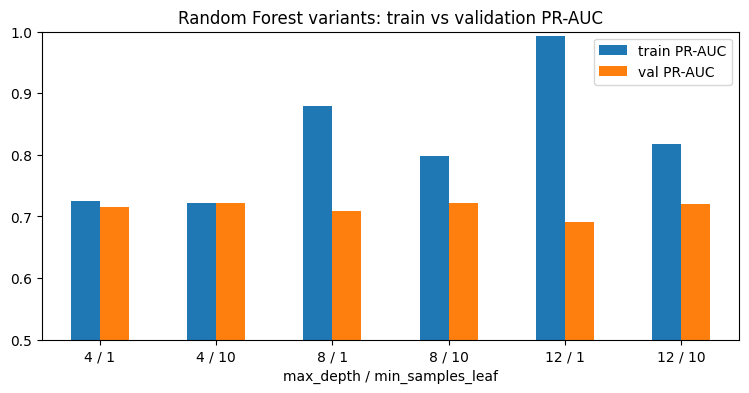

,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Random Forest,train,0.39,0.9380,0.7216,0.6722,0.6659,0.6786
1,Random Forest,validation,0.39,0.9418,0.7219,0.7255,0.6929,0.7613
2,Random Forest,test,0.39,0.9404,0.7078,0.6683,0.6650,0.6716


In [41]:
rf = Pipeline([('prep', make_prep(False)),
               ('clf', RandomForestClassifier(n_estimators=300, max_depth=int(best_rf.max_depth),
                                              min_samples_leaf=int(best_rf.min_samples_leaf),
                                              random_state=42, n_jobs=-1))]).fit(X_train, y_train)
results.append(evaluate(rf, 'Random Forest'))

ax = rf_trials.assign(variant=rf_trials.max_depth.astype(str) + ' / ' + rf_trials.min_samples_leaf.astype(str)) \
              .plot.bar(x='variant', y=['train PR-AUC', 'val PR-AUC'], rot=0, figsize=(9, 4))
ax.set_xlabel('max_depth / min_samples_leaf'); ax.set_ylim(0.5, 1); ax.set_title('Random Forest variants: train vs validation PR-AUC')
save('rf_variants')
plt.show()
results[-1].round(4)

### 9.3 Shallow neural network (Keras)
Two architectures, both with a sigmoid output, Adam optimiser, binary cross-entropy and `EarlyStopping` on the **validation loss** (patience 10, best weights restored):
- **NN-A:** 1 hidden layer (32 ReLU)
- **NN-B:** 2 hidden layers (64 → 32 ReLU) with Dropout 0.2

The class below just wraps "scaler + Keras model" so it has the same `predict_proba` as the scikit-learn models.

In [42]:
class ShallowNN:
    def __init__(self, hidden=(32,), dropout=0.0, seed=42):
        self.hidden, self.dropout, self.seed = hidden, dropout, seed

    def fit(self, X, y, X_val, y_val):
        keras.utils.set_random_seed(self.seed)
        self.prep = make_prep().fit(X)
        model = keras.Sequential([layers.Input(shape=(X.shape[1],))])
        for units in self.hidden:
            model.add(layers.Dense(units, activation='relu'))
            if self.dropout:
                model.add(layers.Dropout(self.dropout))
        model.add(layers.Dense(1, activation='sigmoid'))
        model.compile(optimizer='adam', loss='binary_crossentropy',
                      metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')])
        early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
        self.history = model.fit(self.prep.transform(X), y.values,
                                 validation_data=(self.prep.transform(X_val), y_val.values),
                                 epochs=200, batch_size=32, verbose=0, callbacks=[early_stop])
        self.model = model
        return self

    def predict_proba(self, X):
        p = self.model.predict(self.prep.transform(X), verbose=0).ravel()
        return np.column_stack([1 - p, p])

nn_a = ShallowNN(hidden=(32,)).fit(X_train, y_train, X_val, y_val)
nn_b = ShallowNN(hidden=(64, 32), dropout=0.2).fit(X_train, y_train, X_val, y_val)

nn_trials = pd.DataFrame([{'model': n, 'epochs trained': len(m.history.history['loss']),
                           'train PR-AUC': average_precision_score(y_train, m.predict_proba(X_train)[:, 1]),
                           'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])}
                          for n, m in [('NN-A (32)', nn_a), ('NN-B (64-32, dropout)', nn_b)]]).round(4)
nn_trials

,model,epochs trained,train PR-AUC,val PR-AUC
0,NN-A (32),73,0.7085,0.7053
1,"NN-B (64-32, dropout)",44,0.7115,0.7277


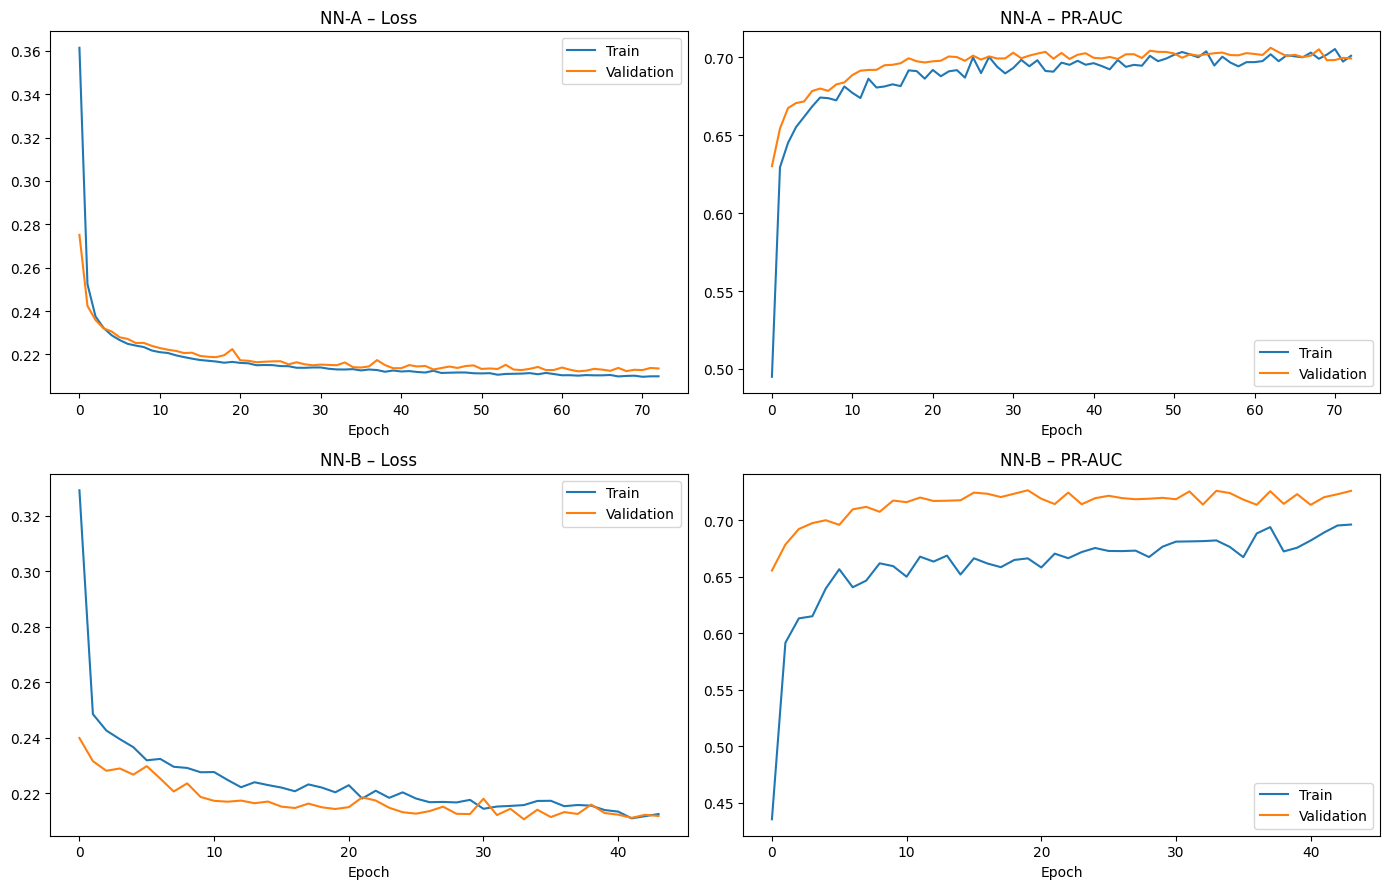

Selected neural network (validation): NN-B (64-32, dropout)


,model,split,threshold,ROC-AUC,PR-AUC,F1,Precision,Recall
0,Shallow NN,train,0.29,0.9400,0.7115,0.6830,0.5949,0.8017
1,Shallow NN,validation,0.29,0.9404,0.7277,0.7153,0.6301,0.8272
2,Shallow NN,test,0.29,0.9285,0.6889,0.6667,0.5852,0.7745


In [43]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for row, (name, m) in enumerate([('NN-A', nn_a), ('NN-B', nn_b)]):
    h = m.history.history
    axes[row, 0].plot(h['loss'], label='Train'); axes[row, 0].plot(h['val_loss'], label='Validation')
    axes[row, 0].set_title(f'{name} – Loss'); axes[row, 0].set_xlabel('Epoch'); axes[row, 0].legend()
    axes[row, 1].plot(h['pr_auc'], label='Train'); axes[row, 1].plot(h['val_pr_auc'], label='Validation')
    axes[row, 1].set_title(f'{name} – PR-AUC'); axes[row, 1].set_xlabel('Epoch'); axes[row, 1].legend()
plt.tight_layout()
save('nn_training_curves')
plt.show()

best_nn_name = nn_trials.loc[nn_trials['val PR-AUC'].idxmax(), 'model']
nn = nn_a if best_nn_name.startswith('NN-A') else nn_b
print('Selected neural network (validation):', best_nn_name)
results.append(evaluate(nn, 'Shallow NN'))
results[-1].round(4)

### 9.4 How much do the scores move with the random seed?
We call some differences "noise" later, so we measure it: the selected RF and NN settings are retrained with 5 different random seeds (same data, same features).

In [44]:
seed_rows = []
for seed in [0, 1, 2, 3, 4]:
    rf_s = Pipeline([('prep', make_prep(False)),
                     ('clf', RandomForestClassifier(n_estimators=300, max_depth=int(best_rf.max_depth),
                                                    min_samples_leaf=int(best_rf.min_samples_leaf),
                                                    random_state=seed, n_jobs=-1))]).fit(X_train, y_train)
    nn_s = ShallowNN(hidden=nn.hidden, dropout=nn.dropout, seed=seed).fit(X_train, y_train, X_val, y_val)
    for name, m in [('Random Forest', rf_s), ('Shallow NN', nn_s)]:
        seed_rows.append({'model': name, 'seed': seed,
                          'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
seed_var = pd.DataFrame(seed_rows).groupby('model')['val PR-AUC'].agg(['mean', 'std', 'min', 'max']).round(4)
seed_var

,mean,std,min,max
model,,,,
Random Forest,0.7180,0.0037,0.7132,0.7224
Shallow NN,0.7182,0.0086,0.7052,0.7269


**Seed check — interpretation:**
- Averaged over 5 seeds, RF and NN reach practically the **same** validation PR-AUC (our run: 0.718 vs 0.718).
- The NN varies more between seeds than the RF (our run: std ≈0.009 vs ≈0.004).
- So a single-run gap between RF and NN says little. Differences of about 0.01 PR-AUC or less (between these models, or between pre-processing orders) are within seed noise.

## 10. Final model comparison

Thresholds were chosen on the validation set; the test set (2022–2024) is evaluated once here.

In [45]:
comparison = pd.concat(results, ignore_index=True)
comparison_wide = comparison.pivot_table(index='model', columns='split',
                                         values=['ROC-AUC', 'PR-AUC', 'F1', 'Precision', 'Recall'])
comparison_wide = comparison_wide.reindex(columns=['train', 'validation', 'test'], level=1).round(3)
comparison_wide

F1                   PR-AUC                   Precision                   ROC-AUC                   Recall                  
split                train validation   test  train validation   test     train validation   test   train validation   test  train validation   test
model                                                                                                                                               
Logistic Regression  0.658      0.722  0.667  0.679      0.698  0.700     0.605      0.646  0.610   0.925      0.931  0.935  0.720      0.819  0.735
Random Forest        0.672      0.725  0.668  0.722      0.722  0.708     0.666      0.693  0.665   0.938      0.942  0.940  0.679      0.761  0.672
Rule: grid position  0.634      0.712  0.649  0.616      0.668  0.647     0.634      0.712  0.650   0.906      0.918  0.914  0.633      0.712  0.647
Shallow NN           0.683      0.715  0.667  0.712      0.728  0.689     0.595      0.630  0.585   0.940      0.940  0.929  0.802      0.827  0.775

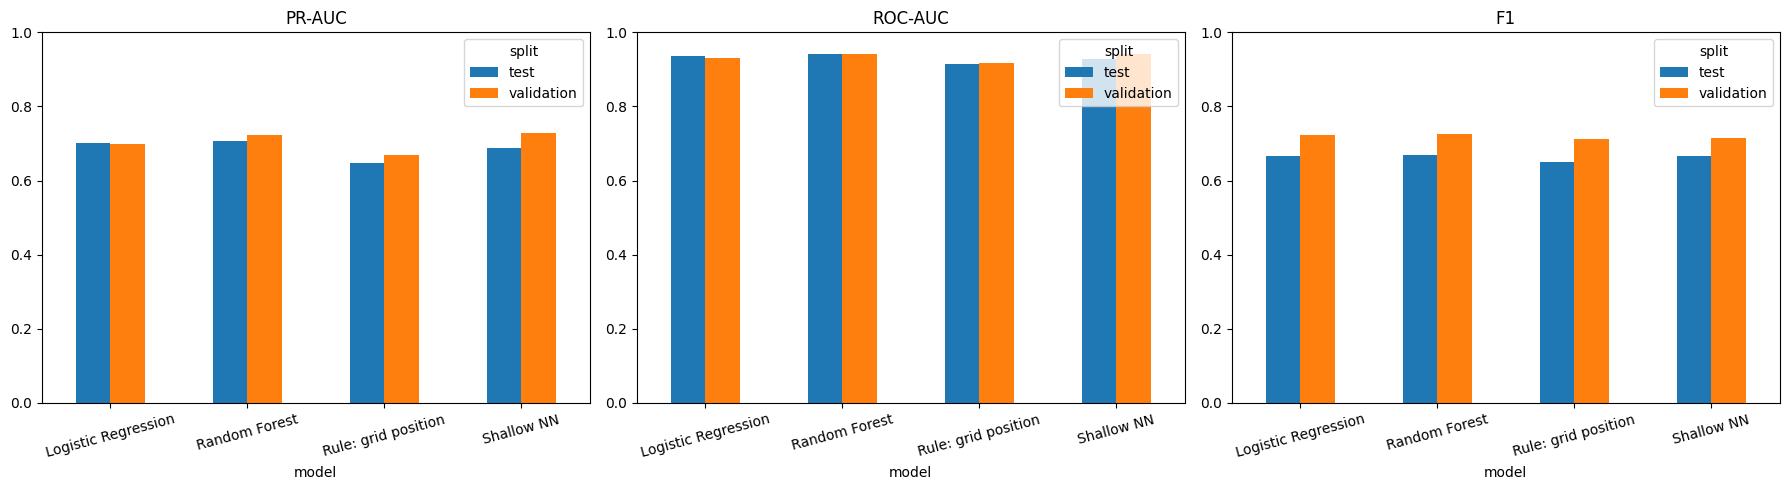

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, ['PR-AUC', 'ROC-AUC', 'F1']):
    comparison[comparison.split != 'train'].pivot(index='model', columns='split', values=metric) \
        .plot.bar(ax=ax, rot=15)
    ax.set_title(metric); ax.set_ylim(0, 1)
plt.tight_layout()
save('model_comparison')
plt.show()

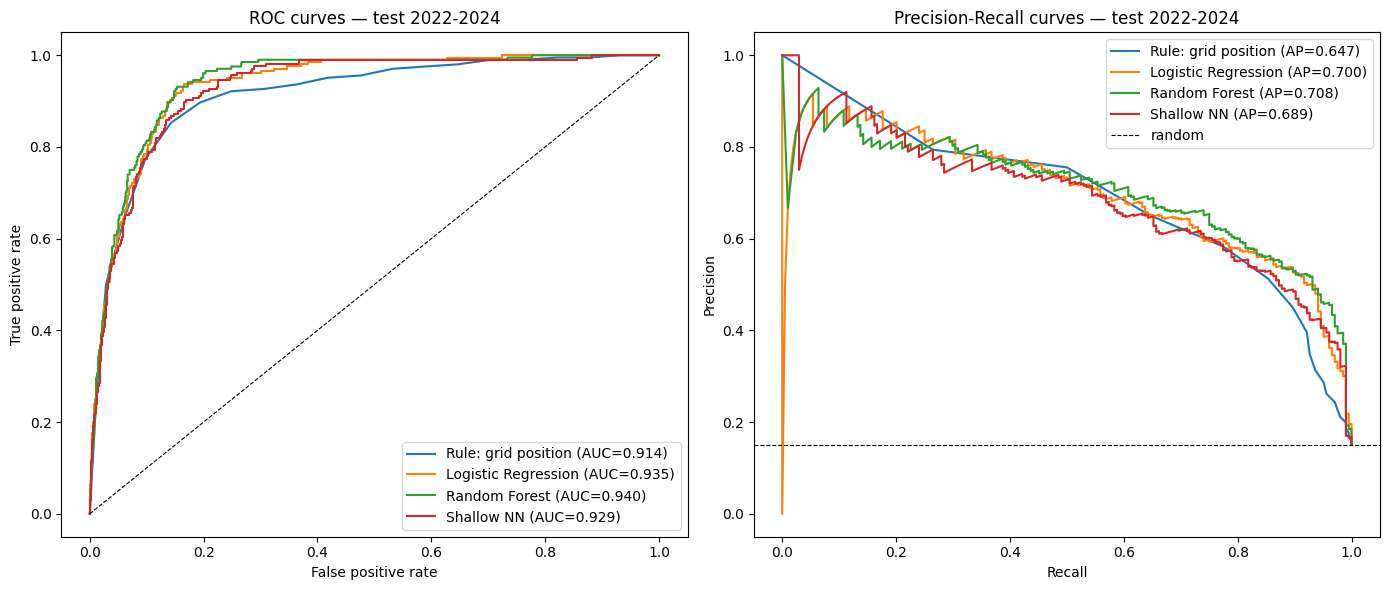

In [47]:
models = {'Rule: grid position': GridRule(), 'Logistic Regression': logreg, 'Random Forest': rf, 'Shallow NN': nn}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
    axes[1].plot(rec, prec, label=f'{name} (AP={average_precision_score(y_test, p):.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=0.8); axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC curves — test 2022-2024'); axes[0].legend()
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=0.8, label='random')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision-Recall curves — test 2022-2024'); axes[1].legend()
plt.tight_layout()
save('roc_pr_curves')
plt.show()

Validation scores used for the choice (test is NOT used):
                     PR-AUC     F1  ROC-AUC
model                                      
Shallow NN            0.728  0.715    0.940
Random Forest         0.722  0.725    0.942
Logistic Regression   0.698  0.722    0.931
Rule: grid position   0.668  0.712    0.918
Final model: Random Forest | threshold chosen on validation: 0.39


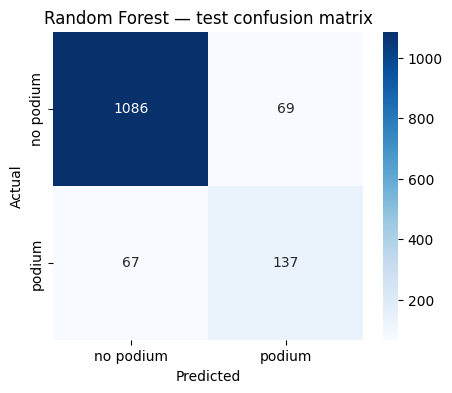

In [48]:
print('Validation scores used for the choice (test is NOT used):')
print(comparison[comparison.split == 'validation'].set_index('model')[['PR-AUC', 'F1', 'ROC-AUC']].sort_values('PR-AUC', ascending=False).round(3).to_string())
FINAL_NAME = 'Random Forest'
final_model = models[FINAL_NAME]
final_threshold = comparison[comparison.model == FINAL_NAME].threshold.iloc[0]
print(f'Final model: {FINAL_NAME} | threshold chosen on validation: {final_threshold:.2f}')

cm = confusion_matrix(y_test, (final_model.predict_proba(X_test)[:, 1] >= final_threshold).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['no podium', 'podium'], yticklabels=['no podium', 'podium'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'{FINAL_NAME} — test confusion matrix')
save('confusion_matrix')
plt.show()

**Model comparison — interpretation**
- **All learned models beat the simple rule** "the better the grid slot, the higher the chance": val PR-AUC 0.67 → 0.70–0.73, test 0.65 → 0.69–0.71. So the extra features (qualifying pace, form, standings) do add information beyond the grid.
- **Baseline logistic regression is already strong** (val 0.70, test 0.70). The relation "better start + stronger car = podium" is mostly linear.
- **Random Forest** (max_depth 4, min_samples_leaf 10) is the best statistical model: val PR-AUC **0.72**, test **0.71**, test ROC-AUC 0.94. The variant table in 9.2 shows that deeper trees **overfit** (train 0.99 vs val 0.69), so the shallow, regularised trees were selected on validation.
- **Shallow NN** scores about the same as the RF on validation (our run: 0.728 vs 0.722 PR-AUC; averaged over 5 seeds both ≈0.718, see 9.4) but lower on the test seasons (our run: 0.689). Its validation score is slightly **optimistic**, because the validation loss was also used to pick the stopping epoch. Its numbers also change a little with the seed and backend (TensorFlow on Kaggle vs PyTorch locally). With about 6k training rows it brings no real gain over the trees.
- **ROC-AUC is ~0.93–0.94 for every model.** Most non-podium rows are easy (cars at the back), which is why **PR-AUC is our primary metric**: it shows the real differences in ranking the few podium finishers. **F1 is the secondary metric**: at the validation-chosen threshold (0.39) the Random Forest finds about **2/3 of the podiums with about 2/3 precision** on the unseen 2022–2024 seasons (test F1 ≈ 0.67). See the confusion matrix.
- **Train vs validation vs test** are close for LR and RF, so there is no strong overfitting. The test seasons (new 2022 car regulations) are only slightly harder.
- **Final model: Random Forest.** On the primary metric it is tied with the NN: the 5-seed averages are practically identical (our run: 0.718 vs 0.718), and the single-run gap (our run: 0.006) is smaller than the NN's seed-to-seed variation (std ≈0.009). It has the best validation F1 and ROC-AUC, it is deterministic, it needs no scaling, and SHAP can explain it exactly. The choice uses validation results only; the test set was not used to choose.

## 11. Feature-group ablation
Remove **one feature group at a time**, retrain Logistic Regression and Random Forest (same hyperparameters as above) and measure the drop in PR-AUC compared with the full feature set. A large drop = the group adds information that the other groups do not already contain.

In [49]:
def make_lr():
    return Pipeline([('prep', make_prep()), ('clf', LogisticRegression(C=best_C, max_iter=1000))])

def make_rf():
    return Pipeline([('prep', make_prep(False)),
                     ('clf', RandomForestClassifier(n_estimators=300, max_depth=int(best_rf.max_depth),
                                                    min_samples_leaf=int(best_rf.min_samples_leaf),
                                                    random_state=42, n_jobs=-1))])

abl = []
for removed in ['none (all features)'] + list(FEATURE_GROUPS):
    feats = [f for f in FEATURES if f not in FEATURE_GROUPS.get(removed, [])]
    for name, make in [('Logistic Regression', make_lr), ('Random Forest', make_rf)]:
        m = make().fit(X_train[feats], y_train)
        abl.append({'removed group': removed, 'model': name,
                    'val PR-AUC': average_precision_score(y_val, m.predict_proba(X_val[feats])[:, 1]),
                    'test PR-AUC': average_precision_score(y_test, m.predict_proba(X_test[feats])[:, 1]),
                    'test ROC-AUC': roc_auc_score(y_test, m.predict_proba(X_test[feats])[:, 1])})
abl = pd.DataFrame(abl)
full = abl[abl['removed group'] == 'none (all features)'].set_index('model')
abl['val PR-AUC drop'] = abl.apply(lambda r: full.loc[r.model, 'val PR-AUC'] - r['val PR-AUC'], axis=1)
abl['test PR-AUC drop'] = abl.apply(lambda r: full.loc[r.model, 'test PR-AUC'] - r['test PR-AUC'], axis=1)
abl.round(4)

,removed group,model,val PR-AUC,test PR-AUC,test ROC-AUC,val PR-AUC drop,test PR-AUC drop
0,none (all features),Logistic Regression,0.6976,0.7002,0.9349,0.0000,0.0000
1,none (all features),Random Forest,0.7219,0.7078,0.9404,0.0000,0.0000
2,grid,Logistic Regression,0.6868,0.6923,0.9320,0.0108,0.0079
3,grid,Random Forest,0.7036,0.6927,0.9355,0.0184,0.0152
4,qualifying,Logistic Regression,0.6972,0.7010,0.9357,0.0004,-0.0008
5,qualifying,Random Forest,0.7116,0.7089,0.9364,0.0103,-0.0010
6,form,Logistic Regression,0.7083,0.7006,0.9335,-0.0107,-0.0005
7,form,Random Forest,0.7248,0.7064,0.9394,-0.0029,0.0015
8,standings,Logistic Regression,0.6993,0.6993,0.9339,-0.0016,0.0008
9,standings,Random Forest,0.7213,0.7006,0.9381,0.0006,0.0072


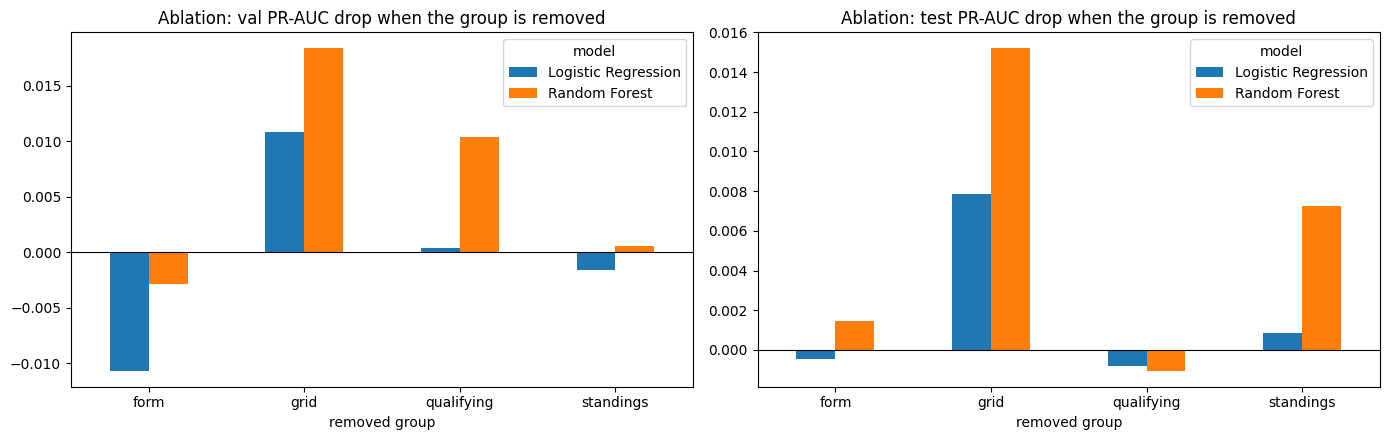

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, col in zip(axes, ['val PR-AUC drop', 'test PR-AUC drop']):
    abl[abl['removed group'] != 'none (all features)'].pivot(index='removed group', columns='model', values=col).plot.bar(ax=ax, rot=0)
    ax.axhline(0, color='black', lw=0.8); ax.set_title(f'Ablation: {col} when the group is removed')
plt.tight_layout()
save('ablation')
plt.show()

**Ablation — interpretation**
- **Grid is the most important group.** Removing it gives the largest drop for both models (RF: −0.018 val / −0.015 test PR-AUC; LR: −0.011 / −0.008).
- **Qualifying:** removing it costs the RF about 0.01 on validation and nothing on test. Most of its information is already in `grid` (correlation 0.9+), and only the pace gap is extra.
- **Standings:** a small drop for the RF on test only (−0.007; ≈0 on validation). LR is unaffected.
- **Form:** removing it does **not** hurt (slightly better for LR on validation). Recent form and standings both measure car/driver strength, so when one group is removed the other substitutes for it.
- **Conclusion:** after training, the information comes mainly from **where the car starts** plus **one measure of car strength**. A smaller model would score almost the same. We keep all four groups: the set was chosen **before** training from the EDA evidence, and removing a group never improves the RF on validation **and** test at the same time. Compared with the seed noise measured in 9.4 (RF std ≈ 0.004), the **grid** drop (0.015–0.018 for the RF) is a real effect, about 4× the noise. The other groups' changes (≤0.01) are close to noise level. (The choice is not based on the test numbers.) The ablation also explains why permutation importance (below) gives these groups little credit.

## 12. Explainability (XAI) — Random Forest
We explain the **Random Forest** (the tree model lets SHAP compute exact explanations with `TreeExplainer`; the methods are the ones used in Lab 4).

> **Important — not causal.** All explanations below describe **what the model relies on to make its predictions**, not what *causes* a podium. A feature being important (e.g. `drv_points_share`) does not mean that having more points makes a driver finish on the podium; it means the model uses it as a signal, often because it is correlated with car and driver strength.

### 12.1 Global — permutation importance (test set)
Shuffle one feature at a time and measure how much the test PR-AUC drops. Bigger drop = the model depends more on that feature.

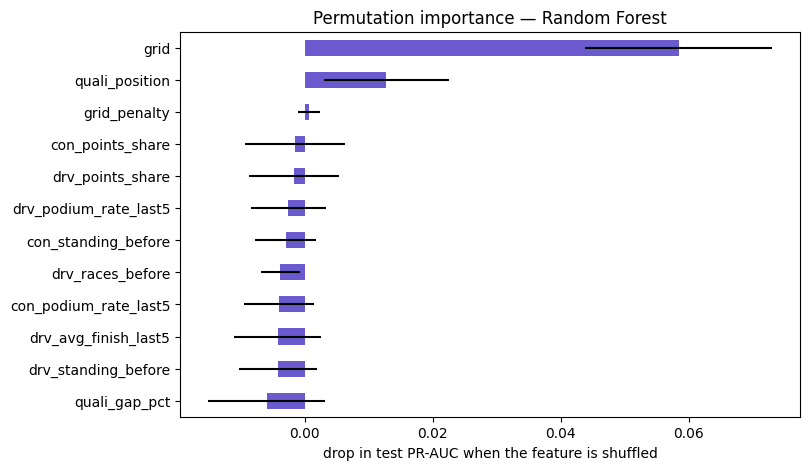

grid                     0.0584
quali_position           0.0128
grid_penalty             0.0007
con_points_share        -0.0014
drv_points_share        -0.0017
drv_podium_rate_last5   -0.0025
con_standing_before     -0.0029
drv_races_before        -0.0038
con_podium_rate_last5   -0.0041
drv_avg_finish_last5    -0.0042
drv_standing_before     -0.0042
quali_gap_pct           -0.0059
dtype: float64

In [51]:
perm = permutation_importance(rf, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=42, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
plt.figure(figsize=(8, 5))
perm_imp.plot.barh(xerr=pd.Series(perm.importances_std, index=FEATURES)[perm_imp.index], color='slateblue')
plt.xlabel('drop in test PR-AUC when the feature is shuffled')
plt.title('Permutation importance — Random Forest')
save('xai_permutation')
plt.show()
perm_imp.sort_values(ascending=False).round(4)

### 12.2 Global — SHAP summary (beeswarm)
SHAP splits each prediction into contributions of the features (positive = pushes towards podium). Each dot is one test row; colour = the feature value (red = high).

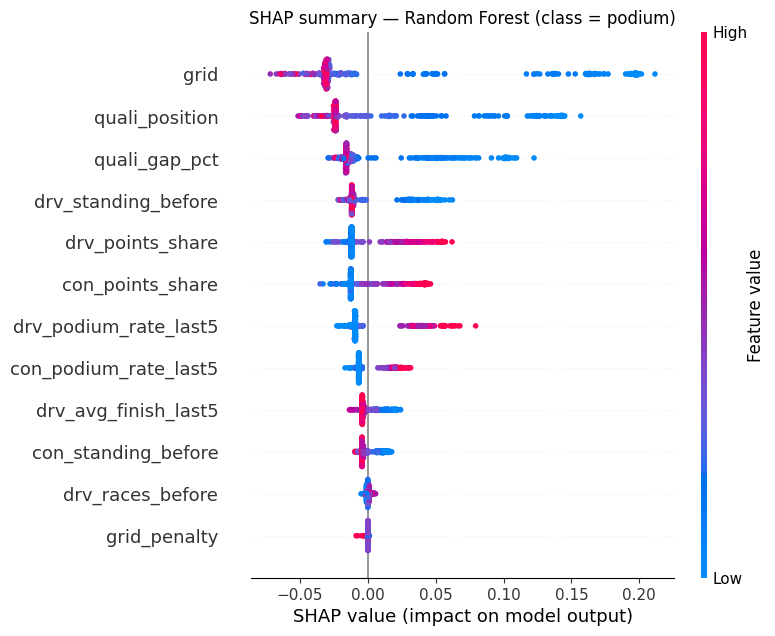

In [52]:
rf_clf = rf.named_steps['clf']
X_test_imp = pd.DataFrame(rf.named_steps['prep'].transform(X_test), columns=FEATURES, index=X_test.index)
X_shap = X_test_imp.sample(400, random_state=42)

explainer_shap = shap.TreeExplainer(rf_clf)
shap_values = explainer_shap.shap_values(X_shap)
if isinstance(shap_values, list):                    # older SHAP: list [class0, class1]
    shap_values = shap_values[1]
elif shap_values.ndim == 3:                          # newer SHAP: (rows, features, classes)
    shap_values = shap_values[:, :, 1]
expected_value = np.array(explainer_shap.expected_value).flatten()[-1]

shap.summary_plot(shap_values, X_shap, feature_names=FEATURES, show=False)
plt.title('SHAP summary — Random Forest (class = podium)')
save('xai_shap_summary')
plt.show()

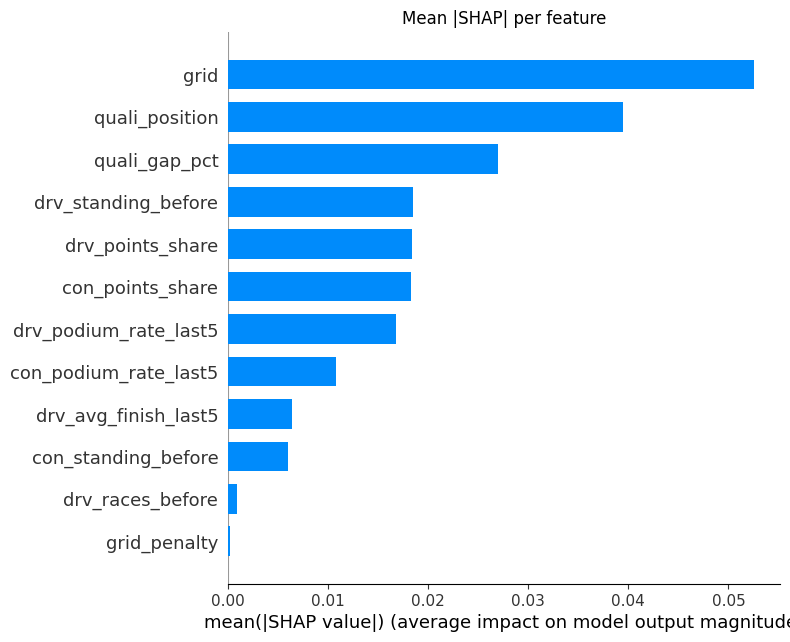

In [53]:
shap.summary_plot(shap_values, X_shap, feature_names=FEATURES, plot_type='bar', show=False)
plt.title('Mean |SHAP| per feature')
save('xai_shap_bar')
plt.show()

**Global explanation — interpretation (not causal)**
- **Permutation importance:** shuffling `grid` lowers test PR-AUC by about **0.06**, `quali_position` by about 0.013, and the other features by ≈0 or slightly less than 0. A near-zero value does **not** mean that a feature is useless. When one correlated feature is shuffled, the model can get the same information from its "twins" (grid ↔ quali_position, form ↔ standings), so the score hardly drops. This agrees with the ablation.
- **SHAP (beeswarm and bar):** the ranking is grid > quali_position > quali_gap_pct > driver standing / points share > constructor points share > recent podium rate. The direction makes sense: **low** grid / qualifying positions and small gaps (blue dots) push the prediction **towards** a podium, by up to +0.2 probability. **High** points shares and recent podium rates (red dots) push it up. Starting further back pushes it down only a little (about −0.05), because most rows are already near the base rate of 14%.
- SHAP shares the credit among correlated features, while permutation importance gives credit only to features that cannot be replaced. That is why SHAP shows form and standings as useful while permutation importance does not.
- **Again: these are associations the model uses, not causes.** For example, a high points share does not cause a podium; it is a signal of a fast car/driver, and that is what actually produces both.

### 12.3 Local — one prediction explained with SHAP (waterfall) and LIME
We pick one test row: **Lando Norris, 2024 Italian GP (Monza)** — he started from pole (P1) and finished 3rd (a podium). We explain the model's probability for this row.

In [54]:
row_mask = (test['year'] == 2024) & (test['driverId'] == 846) & (test['round'] == 16)   # 846 = Lando Norris, round 16 = Monza
assert row_mask.sum() == 1
idx = test[row_mask].index[0]
x_row = X_test_imp.loc[[idx]]
print('Actual result: positionOrder =', test.loc[idx, 'positionOrder'], '| podium =', test.loc[idx, TARGET])
print('Model probability of podium:', round(rf.predict_proba(X_test.loc[[idx]])[0, 1], 3))
x_row.T.rename(columns={idx: 'feature value'})

Actual result: positionOrder = 3 | podium = 1
Model probability of podium: 0.758


,feature value
grid,1.000000
grid_penalty,0.000000
quali_position,1.000000
quali_gap_pct,0.000000
drv_podium_rate_last5,0.600000
drv_avg_finish_last5,6.200000
con_podium_rate_last5,1.000000
drv_races_before,119.000000
drv_standing_before,2.000000
drv_points_share,0.762712


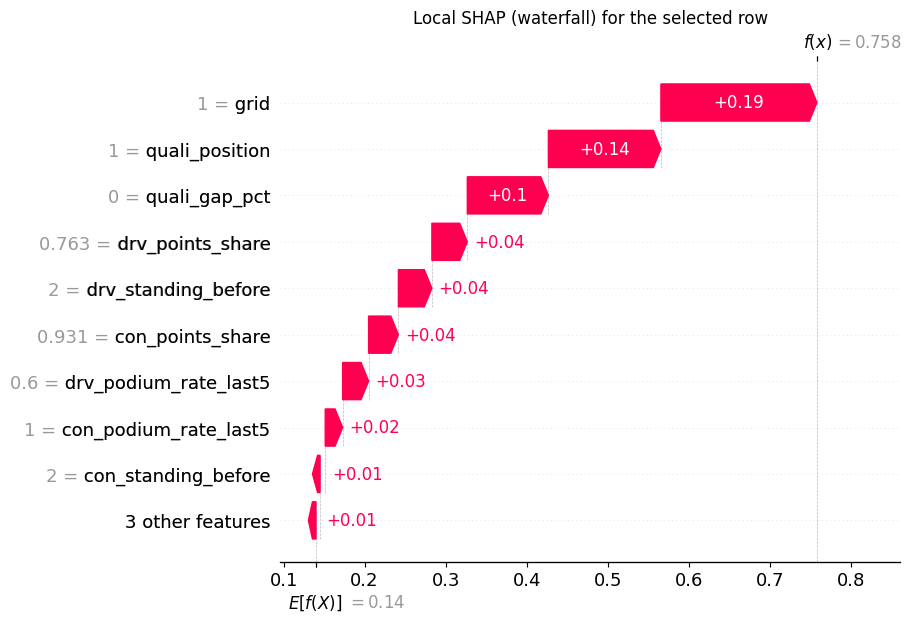

In [55]:
sv_row = explainer_shap.shap_values(x_row)
sv_row = sv_row[1] if isinstance(sv_row, list) else (sv_row[:, :, 1] if sv_row.ndim == 3 else sv_row)
shap.plots.waterfall(shap.Explanation(values=sv_row[0], base_values=expected_value,
                                      data=x_row.values[0], feature_names=FEATURES), show=False)
plt.title('Local SHAP (waterfall) for the selected row')
save('xai_shap_waterfall')
plt.show()

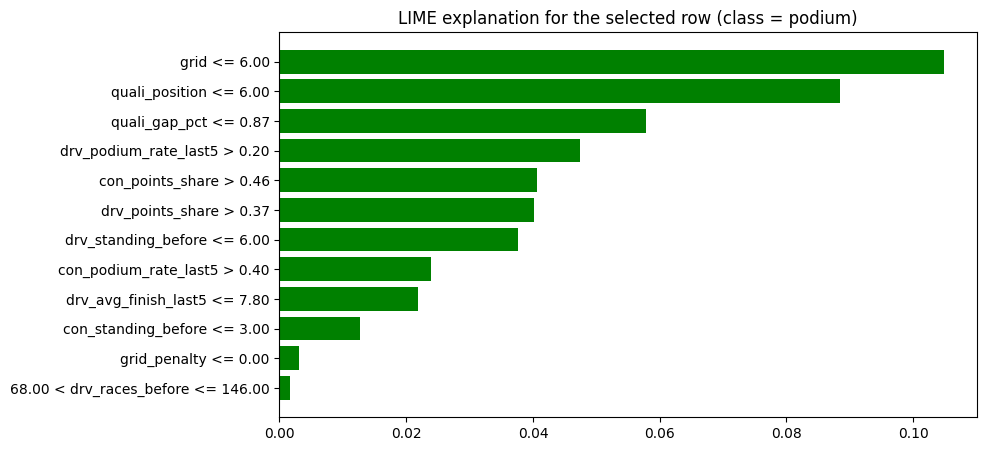

,rule,weight
0,grid <= 6.00,0.1048
1,quali_position <= 6.00,0.0884
2,quali_gap_pct <= 0.87,0.0579
3,drv_podium_rate_last5 > 0.20,0.0474
4,con_points_share > 0.46,0.0406
5,drv_points_share > 0.37,0.0401
6,drv_standing_before <= 6.00,0.0376
7,con_podium_rate_last5 > 0.40,0.0240
8,drv_avg_finish_last5 <= 7.80,0.0218
9,con_standing_before <= 3.00,0.0128


In [56]:
explainer_lime = lime.lime_tabular.LimeTabularExplainer(
    rf.named_steps['prep'].transform(X_train), feature_names=FEATURES,
    class_names=['no podium', 'podium'], discretize_continuous=True, random_state=42)
predict_fn = rf_clf.predict_proba
exp = explainer_lime.explain_instance(x_row.values[0], predict_fn, num_features=len(FEATURES), labels=(1,))
fig = exp.as_pyplot_figure(label=1)
fig.set_size_inches(9, 5)
plt.title('LIME explanation for the selected row (class = podium)')
save('xai_lime')
plt.show()
pd.DataFrame(exp.as_list(label=1), columns=['rule', 'weight']).round(4)

**Local explanation — interpretation (Norris, Monza 2024, actual result: 3rd → podium)**
- The model gives **0.76** probability of a podium, which is above the 0.39 threshold, so it predicts *podium*. This is correct.
- **SHAP waterfall:** starting from the average prediction (0.14), the largest pushes up come from **grid = 1 (+0.19)**, **quali_position = 1 (+0.14)** and **quali_gap_pct = 0 (+0.10)**, i.e. he was on pole. Smaller pushes come from his strong season: points share 0.76 and P2 in the championship (+0.04 each), team points share 0.93 (+0.04), and podiums in 3 of his last 5 races (+0.03).
- **LIME** shows the same story with rules in probability units: `grid <= 6`, `quali_position <= 6` and `quali_gap_pct <= 0.87` have the largest positive weights, followed by the form and standings rules. SHAP and LIME agree on the order of the top features. Their numbers differ because LIME fits a local linear model on perturbed samples, while SHAP splits the exact prediction.
- **Not causal:** the explanation says *why the model gave this probability*, not *why Norris finished on the podium*.

## 13. Inference function
`predict_podium(record)` takes a dictionary with the pre-race features of one driver in one race and returns the podium probability, the yes/no decision (using the threshold chosen on validation) and which features were missing.
**Missing features are allowed:**
- If the qualifying position is missing but the grid slot is known, it is set to the grid slot (and `grid_penalty` to 0). The median (P11) would contradict a known grid slot, e.g. grid 1 with qualifying 11.
- All other missing features are filled by the same median imputer that was fitted on the training data (inside the model pipeline).
- So the function still works for e.g. a rookie with no form history or a race without qualifying data.

In [57]:
def predict_podium(record, model=final_model, threshold=final_threshold):
    """record: dict {feature name: value}. Unknown / missing features may be left out."""
    unknown = set(record) - set(FEATURES)
    if unknown:
        raise ValueError(f'Unknown features: {sorted(unknown)} — post-race information is not accepted')
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], dtype=float)
    missing = [f for f in FEATURES if pd.isna(row.at[0, f])]
    if pd.isna(row.at[0, 'quali_position']) and pd.notna(row.at[0, 'grid']):
        row.at[0, 'quali_position'] = row.at[0, 'grid']      # best guess: qualified where he starts
        row.at[0, 'grid_penalty'] = 0
    prob = float(model.predict_proba(row)[0, 1])
    return {'podium_probability': round(prob, 3),
            'predicted_podium': bool(prob >= threshold),
            'missing_features (imputed)': missing}

In [58]:
# Demo 1 — a complete record (real pre-race features of the row explained above)
complete_record = test.loc[idx, FEATURES].to_dict()
assert not any(pd.isna(v) for v in complete_record.values())
print('Complete record:', {k: round(v, 3) for k, v in complete_record.items()})
print(predict_podium(complete_record))

Complete record: {'grid': 1, 'grid_penalty': 0.0, 'quali_position': 1.0, 'quali_gap_pct': 0.0, 'drv_podium_rate_last5': 0.6, 'drv_avg_finish_last5': 6.2, 'con_podium_rate_last5': 1.0, 'drv_races_before': 119, 'drv_standing_before': 2.0, 'drv_points_share': 0.763, 'con_standing_before': 2.0, 'con_points_share': 0.931}
{'podium_probability': 0.758, 'predicted_podium': True, 'missing_features (imputed)': []}


In [59]:
# Demo 2 — a partially-missing record: the same driver/race, but the qualifying data and the
#          championship standing are missing (as happens for many pre-2003 races).
partial_record = {k: v for k, v in complete_record.items()
                  if k not in ['quali_position', 'quali_gap_pct', 'grid_penalty', 'drv_standing_before']}
print('Partial record:', {k: round(v, 3) for k, v in partial_record.items()})
print(predict_podium(partial_record))

Partial record: {'grid': 1, 'drv_podium_rate_last5': 0.6, 'drv_avg_finish_last5': 6.2, 'con_podium_rate_last5': 1.0, 'drv_races_before': 119, 'drv_points_share': 0.763, 'con_standing_before': 2.0, 'con_points_share': 0.931}


{'podium_probability': 0.609, 'predicted_podium': True, 'missing_features (imputed)': ['grid_penalty', 'quali_position', 'quali_gap_pct', 'drv_standing_before']}


In [60]:
# Demo 3 — a very sparse record: only the grid slot is known (e.g. a debutant with no history)
print(predict_podium({'grid': 4, 'drv_races_before': 0}))

{'podium_probability': 0.123, 'predicted_podium': False, 'missing_features (imputed)': ['grid_penalty', 'quali_position', 'quali_gap_pct', 'drv_podium_rate_last5', 'drv_avg_finish_last5', 'con_podium_rate_last5', 'drv_standing_before', 'drv_points_share', 'con_standing_before', 'con_points_share']}


**What the demos show**
- **Complete record (pole, strong season):** high podium probability (≈0.76), predicted *podium*. This is correct, as he finished 3rd.
- **Partial record:** the qualifying position is missing, so it is set to the grid slot (P1). The qualifying gap and the standing are filled with the **training medians** (a midfield gap of ~1.8%). The model loses the information "he was the fastest by a margin", so the probability drops (0.76 → ≈0.61), but it still stays above the 0.39 threshold thanks to grid = 1 and the strong form/points. Missing information makes the model more cautious; it does not crash.
- **Sparse record:** with only grid P4 and no history, every other feature takes a median (weak) value, so the probability is low (≈0.12). The function always returns the list of imputed features, so the user knows how much was guessed.

## 14. Conclusions & limitations

**Summary**
- **Data:**
  - The 14 raw tables were audited: all primary keys are unique and all foreign keys reconcile.
  - 160k `\N` sentinels were converted to real missing values, and dates and durations were given proper types.
  - Two label inconsistencies were fixed.
  - 91 duplicate driver-race rows (1950s shared drives) were removed with a documented rule. The modeling table has exactly one row per `(raceId, driverId)`: 8,970 rows, 2003–2024.
- **Data-engineering answers:**
  - **Q1:** front-row conversion is highest at Monza/Monaco before 2014 and at Suzuka/Yas Marina/Monaco after 2014. The ranking changes strongly (Spearman ≈0.21), and grid ≠ qualifying because of penalties.
  - **Q2:** there is no home advantage once grid position is controlled.
  - **Q3:** Caterham/Lotus/Toro Rosso/McLaren in 2014–2021 and Alfa Romeo/Alpine in 2022–2024 had the highest mechanical-retirement rates, and overall reliability improved.
- **Model:** 12 leakage-safe features in 4 groups. The **Random Forest** reaches PR-AUC ≈0.71, ROC-AUC ≈0.94 and F1 ≈0.67 on the unseen 2022–2024 seasons, beating the logistic-regression baseline and the grid-only rule. The shallow NN is comparable on validation but slightly worse on test.
- **Main drivers of the prediction:** grid and qualifying, then car/driver strength (standings and form). These are model associations, **not causal effects**.

**Known limitations**
- **Qualifying coverage drift:** qualifying data is missing for most races before 2003, so the model is trained only on 2003–2024. It is not valid for earlier eras without qualifying data; the inference function then relies on imputation, which pulls predictions towards the average.
- **Era sensitivity:**
  - Rule changes (hybrid engines in 2014, new cars in 2022) change how dominant teams are. The test seasons are a new regulation era.
  - Points systems changed; we use points *shares* to reduce this.
  - Field size and race count per season also vary.
- **Correlated features:** grid, qualifying, form and standings overlap. Single-feature importance values must be read together with the ablation.
- **Simplifications:**
  - pit-lane starters are placed at the back of the grid
  - best qualifying time is the minimum of Q1/Q2/Q3 (session conditions can differ)
  - home country is taken from nationality, not birthplace
  - the list of "mechanical" statuses is a judgement call (documented in Q3)
  - sprint results are not used
- **Calibration:** the model outputs are used as *scores* for ranking and the threshold. They are not calibrated probabilities (no reliability curve / Brier score was checked), so "0.76" should be read as "very likely relative to other entries".
- **Qualifying format:** in 2003–2005 qualifying used single laps with race fuel / aggregate times, so `quali_gap_pct` in those seasons mixes pace and fuel load.
- **Each row is predicted independently:** the model is not forced to predict exactly 3 podiums per race.
- **Threshold:** the 0.39 threshold maximises F1 on 2018–2021. A different use (e.g. betting, where precision matters more) would need a different threshold.